# Chapter 1 Hands-On Project: Vector Spaces, Inner Products, Regularization & Optimization Geometry

Welcome to the companion coding project for **Chapter 1: Vector Space and Inner Product** of *Mathematics for AI and Machine Learning* ([https://math4ai.org](https://math4ai.org)).

In this notebook, we bridge the abstract mathematical structures of Chapter 1 with practical **NumPy**, **Scikit-Learn**, and **PyTorch** implementations:

1. **Part 1 — Inner Products, Vector Projections & Hyperplane Geometry**:
   - Dot product, cosine similarity, Cauchy–Schwarz inequality, and orthogonal energy additivity ($\|\mathbf{u}+\mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2$).
   - Vector-vector projection via outer product operators $P = \frac{\mathbf{v}\mathbf{v}^\top}{\mathbf{v}^\top\mathbf{v}}$ and orthogonal decomposition $\mathbf{u} = \mathbf{p} + \mathbf{d}_\perp$.
   - Point-to-hyperplane distance: comparing **Linear Regression vertical residuals** ($r = y - \hat{y}$) against **SVM orthogonal geometric margins** ($d_\perp$).
2. **Part 2 — Norms Geometry ($\ell_p$, $\text{Std-}\ell_2$, Mahalanobis) & Anomaly Detection**:
   - Visualizing the unit balls of $\ell_1$, $\ell_2$, $\ell_4$, $\ell_\infty$, Standardized Euclidean ($\text{Std-}\ell_2$), and Mahalanobis ($\|\mathbf{v}\|_M = \sqrt{\mathbf{v}^\top \Sigma^{-1}\mathbf{v}}$) norms.
   - Practical **Out-of-Distribution (OOD) / Anomaly Detection** on correlated features where Euclidean distance fails and Mahalanobis distance succeeds.
3. **Part 3 — Hilbert vs. Banach Spaces in Practice: Ridge ($\ell_2$) vs. LASSO ($\ell_1$) Regularization**:
   - Testing the **Parallelogram Law** to see why $(\mathbb{R}^d, \|\cdot\|_2)$ is a Hilbert space while $(\mathbb{R}^d, \|\cdot\|_1)$ is only a Banach space.
   - Visualizing the geometric origin of sparsity ($\ell_1$ diamond corners vs. $\ell_2$ smooth circle).
   - **Hands-on Ridge & LASSO Regression** (both from scratch via Proximal Gradient Descent / ISTA and with `scikit-learn`): recovering sparse true weights in high-dimensional noisy data and plotting full **regularization paths**.
4. **Part 4 — Banach Space Completeness, Cauchy Sequences & Weight Decay (`SGD`, `Adam`, `AdamW`)**:
   - Matrix optimization in Banach space $(\mathbb{R}^{m\times n}, \|\cdot\|_F)$ and the **Weight Decay Quadratic Bowl** pull ($\mathbf{W}_{\text{opt}} = \frac{2}{2+\lambda}\mathbf{W}^*$).
   - **Counterexample**: Why constant-LR minibatch SGD decreases loss without forming a Cauchy sequence ($\|\mathbf{W}_{k+1}-\mathbf{W}_k\|_F \not\to 0$), and how learning-rate decay restores Cauchy convergence.
   - **PyTorch Deep Learning Practical**: Comparing Unregularized MLP, SGD + Weight Decay, Adam + coupled $\ell_2$ penalty, and **AdamW (Decoupled Weight Decay)**.
5. **Part 5 — Gram–Schmidt Orthonormalization & Scaled Dot-Product Attention in Hilbert Space**:
   - Constructing an orthonormal basis via Gram–Schmidt and implementing **Transformer Scaled Dot-Product Attention** ($\text{softmax}(QK^\top / \sqrt{d_k})V$), verifying why the $\frac{1}{\sqrt{d_k}}$ scaling prevents vanishing gradients.
6. **Part 6 (Lab 6) — Representation Stability in Residual Networks (ResNet)**: The $L$-layer linear growth cone $[\|\mathbf{x}_0\|_2 \pm L\epsilon]$ vs. multiplicative explosion, and the gradient norm highway under backpropagation.
7. **Part 7 (Lab 7) — Weights as Vectors: Linear Mode Connectivity**: Flattened network parameters $\mathbf{w} \in \mathbb{R}^P$, the linear path $(1-\alpha)W_A + \alpha W_B$, and zero loss barriers between models sharing a pretraining basin.
8. **Part 8 (Lab 8) — Random Vectors in High Dimension: Concentration of Measure**: Isotropic vectors on $\mathbb{S}^{d-1}$, inner products concentrating around $0$ with spread $1/\sqrt{d}$, pairwise distances $\|\mathbf{u}-\mathbf{v}\|_2 \approx \sqrt{2}$, and the geometric derivation of Transformer attention scaling $1/\sqrt{d_k}$.
9. **Part 9 (Lab 9) — Random Projections & Johnson–Lindenstrauss Lemma**: Preserving pairwise $\ell_2$ metrics within $1\pm\varepsilon$ as dimension collapses from $d=5{,}000$ to $k \ll d$, benchmarking empirical distortion against the JL theoretical bound.
10. **Part 10 (Lab 10) — SimHash for Approximate Nearest Neighbors (LSH)**: Locality-Sensitive Hashing with random hyperplanes, collision identity $P(h(\mathbf{u})=h(\mathbf{v})) = 1 - \frac{\theta}{\pi}$, and Top-10 ANN retrieval recall against Hamming bit budgets.


In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.linear_model import Ridge, Lasso

# Global plotting and reproducibility settings
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10
})
print("Environment initialized successfully!")

def save_fig(name, **kw):
    # Writes the figure premium.md shows; skipped when ../img is absent (e.g. on Colab).
    if os.path.isdir("../img"):
        plt.savefig(f"../img/{name}", **kw)

Environment initialized successfully!


---
## Part 1: Inner Products, Vector Projections & Hyperplane Distance

### 1.1 Inner Product, Unit Vectors, Cauchy–Schwarz & Energy Additivity

For column vectors $\mathbf{u}, \mathbf{v} \in \mathbb{R}^d$, the standard inner product is:
$$\langle \mathbf{u}, \mathbf{v} \rangle = \mathbf{u}^\top \mathbf{v} = \sum_{i=0}^{d-1} u_i v_i = \|\mathbf{u}\|_2 \|\mathbf{v}\|_2 \cos\theta$$

Key theorems from Chapter 1:
- **Cauchy–Schwarz Inequality**: $|\langle \mathbf{u}, \mathbf{v} \rangle| \le \|\mathbf{u}\|_2 \|\mathbf{v}\|_2$, with equality iff $\mathbf{u}$ and $\mathbf{v}$ are collinear.
- **Triangle Inequality**: $\|\mathbf{u} + \mathbf{v}\|_2 \le \|\mathbf{u}\|_2 + \|\mathbf{v}\|_2$.
- **Energy Additivity (Pythagorean Theorem)**: $\|\mathbf{u} + \mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2 + 2\langle \mathbf{u}, \mathbf{v} \rangle$. When $\mathbf{u} \perp \mathbf{v}$ ($\langle \mathbf{u}, \mathbf{v} \rangle = 0$), energy is strictly additive: $\|\mathbf{u} + \mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2$.

### 1.2 Vector-Vector Projection & Outer Product Matrix

Given $\mathbf{v} \in \mathbb{R}^d$ and target direction $\mathbf{x} \in \mathbb{R}^d$, the orthogonal projection of $\mathbf{v}$ onto $\mathbf{x}$ is:
$$\mathbf{p} = \frac{\langle \mathbf{v}, \mathbf{x} \rangle}{\|\mathbf{x}\|_2^2} \mathbf{x} = \underbrace{\left(\frac{\mathbf{x}\mathbf{x}^\top}{\mathbf{x}^\top \mathbf{x}}\right)}_{P_{\mathbf{x}}} \mathbf{v}, \qquad \mathbf{r}_{\perp} = \mathbf{v} - \mathbf{p}$$
where $P_{\mathbf{x}} = \frac{\mathbf{x}\mathbf{x}^\top}{\mathbf{x}^\top \mathbf{x}} \in \mathbb{R}^{d \times d}$ is the rank-1 **projection matrix** formed by the outer product $\mathbf{x}\mathbf{x}^\top$ divided by the inner product $\mathbf{x}^\top \mathbf{x}$ (`outer / inner` in the code; this matrix form previews the projection matrix of Chapter 2).

In [2]:
# 1. Vector-Vector Projection via Outer Product (x x^T) over Inner Product (x^T x)
v = np.array([[1.0, 2.0, 3.0]]).T   # Target vector to project (3x1)
x = np.array([[2.0, 3.0, 1.0]]).T   # Direction vector (3x1)

outer = x @ x.T                     # Outer product: 3x3 matrix
inner = (x.T @ x).item()            # Inner product (squared L2 norm): scalar 14.0
P_x = outer / inner                 # Rank-1 Orthogonal Projection Matrix

p = P_x @ v                         # Projected vector p onto span(x)
r_perp = v - p                      # Orthogonal component v - p

print("Outer product matrix x x^T:\n", outer)
print(f"Inner product scalar x^T x: {inner:.1f}")
print(f"Projected vector p^T:           {p.ravel().round(6)}")
print(f"Orthogonal component r_perp^T:  {r_perp.ravel().round(6)}")

# Verify orthogonality <p, r_perp> == 0 and Energy Additivity ||v||_2^2 == ||p||_2^2 + ||r_perp||_2^2
inner_p_r = (p.T @ r_perp).item()
energy_v = np.linalg.norm(v) ** 2
energy_sum = np.linalg.norm(p) ** 2 + np.linalg.norm(r_perp) ** 2
print(f"\nVerification:")
print(f"  <p, r_perp> = {inner_p_r:.2e} (Orthogonal!)")
print(f"  ||v||_2^2 = {energy_v:.6f}  vs.  ||p||_2^2 + ||r_perp||_2^2 = {energy_sum:.6f}")
print(f"  Idempotency P_x^2 == P_x: {np.allclose(P_x @ P_x, P_x)}")

Outer product matrix x x^T:
 [[4. 6. 2.]
 [6. 9. 3.]
 [2. 3. 1.]]
Inner product scalar x^T x: 14.0
Projected vector p^T:           [1.571429 2.357143 0.785714]
Orthogonal component r_perp^T:  [-0.571429 -0.357143  2.214286]

Verification:
  <p, r_perp> = 0.00e+00 (Orthogonal!)
  ||v||_2^2 = 14.000000  vs.  ||p||_2^2 + ||r_perp||_2^2 = 14.000000
  Idempotency P_x^2 == P_x: True


### 1.3 Point-to-Hyperplane Distance: Regression Residual ($r$) vs. Orthogonal Distance ($d_\perp$)

In Section *"Example: Orthogonal Distance from Point to Hyperplane"* of Chapter 1:
- A hyperplane in $\mathbb{R}^d$ is defined by $\boldsymbol{\theta}^\top \mathbf{x} = b$. The signed orthogonal distance from a point $\mathbf{u} \in \mathbb{R}^d$ to the hyperplane is:
  $$d_{\perp} = \frac{\boldsymbol{\theta}^\top \mathbf{u} - b}{\|\boldsymbol{\theta}\|_2}$$
- In **Linear Regression**, $\hat{y} = \boldsymbol{\theta}^\top \mathbf{x} + b$ defines a hyperplane $\boldsymbol{\theta}^\top \mathbf{x} - y + b = 0$ in the augmented space $(\mathbf{x}, y) \in \mathbb{R}^{d+1}$ with normal vector $\tilde{\boldsymbol{\theta}} = [\boldsymbol{\theta}^\top, -1]^\top$.
- For the Chapter 1 example $\boldsymbol{\theta} = [2, -1]^\top$, $b = 5$, and data point $\mathbf{x} = [1, 2]^\top, y = 3$:
  - **Prediction**: $\hat{y} = 2(1) - 1(2) + 5 = 5$
  - **Vertical Prediction Residual**: $r = y - \hat{y} = 3 - 5 = -2$ (minimized by Least Squares)
  - **Orthogonal Geometric Distance**: $|d_{\perp}| = \frac{|r|}{\sqrt{\|\boldsymbol{\theta}\|_2^2 + 1}} = \frac{2}{\sqrt{6}} \approx 0.8165$ (optimized by Support Vector Machines)

Predicted y_hat:             5.0000
Prediction Residual r:       -2.0000
Orthogonal Distance |d_perp|: 0.816497  (2/sqrt(6) = 0.816497)


<>:28: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_3992994/2465117935.py:28: SyntaxWarning: invalid escape sequence '\h'
  ax.scatter([x_pt[0]], [y_hat], color="#2ca02c", s=80, zorder=5, label=f"Predicted Point $(x_0=1, \hat{{y}}=5)$")


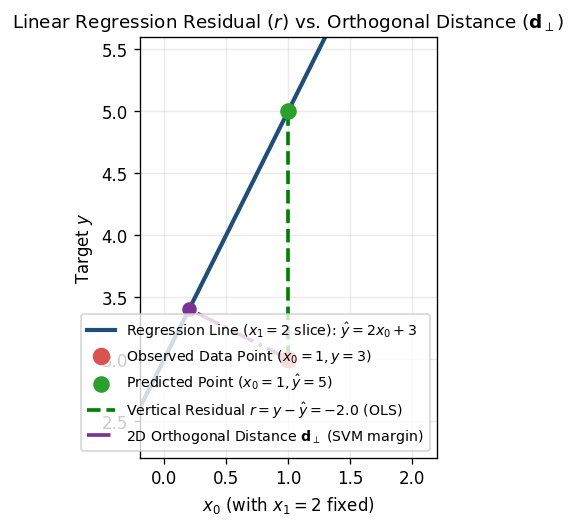

In [3]:
# Verify the exact Chapter 1 numerical example
theta = np.array([2.0, -1.0])
b = 5.0
x_pt = np.array([1.0, 2.0])
y_pt = 3.0

y_hat = theta @ x_pt + b
residual_r = y_pt - y_hat

# Augmented space normal vector: tilde_theta = [theta_0, theta_1, -1]^T, offset = -b
tilde_theta = np.append(theta, -1.0)
u_aug = np.append(x_pt, y_pt)
d_perp = (tilde_theta @ u_aug + b) / np.linalg.norm(tilde_theta)

print(f"Predicted y_hat:             {y_hat:.4f}")
print(f"Prediction Residual r:       {residual_r:.4f}")
print(f"Orthogonal Distance |d_perp|: {abs(d_perp):.6f}  (2/sqrt(6) = {2/np.sqrt(6):.6f})")

# 2D cross-section visualization (fixing x_1 = 2, varying x_0)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
x0_vals = np.linspace(-0.5, 2.5, 200)
x1_fixed = 2.0
# Line in 2D slice (x_0, y) when x_1 = 2: y = 2*x_0 - 2 + 5 = 2*x_0 + 3
y_line = theta[0] * x0_vals + theta[1] * x1_fixed + b

ax.plot(x0_vals, y_line, color="#1f4e78", lw=2.5, label=r"Regression Line ($x_1=2$ slice): $\hat{y} = 2x_0 + 3$")
ax.scatter([x_pt[0]], [y_pt], color="#d9534f", s=90, zorder=5, label=f"Observed Data Point $(x_0=1, y=3)$")
ax.scatter([x_pt[0]], [y_hat], color="#2ca02c", s=80, zorder=5, label=f"Predicted Point $(x_0=1, \hat{{y}}=5)$")

# Vertical residual r (green dashed)
ax.plot([x_pt[0], x_pt[0]], [y_pt, y_hat], "g--", lw=2.2, label=f"Vertical Residual $r = y - \\hat{{y}} = {residual_r:.1f}$ (OLS)")

# Orthogonal foot in 2D slice: line is 2*x_0 - y + 3 = 0, normal n_2d = [2, -1]
n_2d = np.array([theta[0], -1.0])
pt_2d = np.array([x_pt[0], y_pt])
foot_2d = pt_2d - ((n_2d @ pt_2d + 3.0) / (n_2d @ n_2d)) * n_2d
ax.plot([pt_2d[0], foot_2d[0]], [pt_2d[1], foot_2d[1]], color="#7b3294", ls="-.", lw=2.2,
        label=r"2D Orthogonal Distance $\mathbf{d}_{\perp}$ (SVM margin)")
ax.scatter([foot_2d[0]], [foot_2d[1]], color="#7b3294", s=60, zorder=5)

ax.set_aspect("equal")
ax.set_xlim(-0.2, 2.2)
ax.set_ylim(2.2, 5.6)
ax.set_xlabel("$x_0$ (with $x_1 = 2$ fixed)")
ax.set_ylabel("Target $y$")
ax.set_title("Linear Regression Residual ($r$) vs. Orthogonal Distance ($\\mathbf{d}_{\\perp}$)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

---
## Part 2: Norms Geometry ($\ell_p$, $\text{Std-}\ell_2$, Mahalanobis) & Anomaly Detection

### 2.1 Visualizing the 6 Unit Balls from Chapter 1

In Section *"Norms"*, Chapter 1 defines six fundamental norms on $\mathbb{R}^d$:
1. **Manhattan ($\ell_1$)**: $\|\mathbf{v}\|_1 = \sum_{i} |v_i|$ (diamond unit ball — sharp corners on axes)
2. **Euclidean ($\ell_2$)**: $\|\mathbf{v}\|_2 = \sqrt{\sum_i v_i^2}$ (circular unit ball — isotropic)
3. **Minkowski ($\ell_4$)**: $\|\mathbf{v}\|_4 = \left(\sum_i |v_i|^4\right)^{1/4}$ (rounded square / squircle)
4. **Chebyshev ($\ell_\infty$)**: $\|\mathbf{v}\|_\infty = \max_i |v_i|$ (axis-aligned square)
5. **Standardized Euclidean ($\text{Std-}\ell_2$)**: $\|\mathbf{v}\|_{\text{Std-}\ell_2} = \sqrt{\sum_i (v_i / \sigma_i)^2}$ (axis-aligned ellipse — implicit geometry of **Adam/RMSProp** and **BatchNorm/LayerNorm**)
6. **Mahalanobis Norm (M-norm)**: $\|\mathbf{v}\|_M = \sqrt{\mathbf{v}^\top \Sigma^{-1} \mathbf{v}}$ (rotated ellipse — accounts for feature correlations; implicit geometry of **Natural Gradient / Shampoo / Muon** and **OOD detection**).

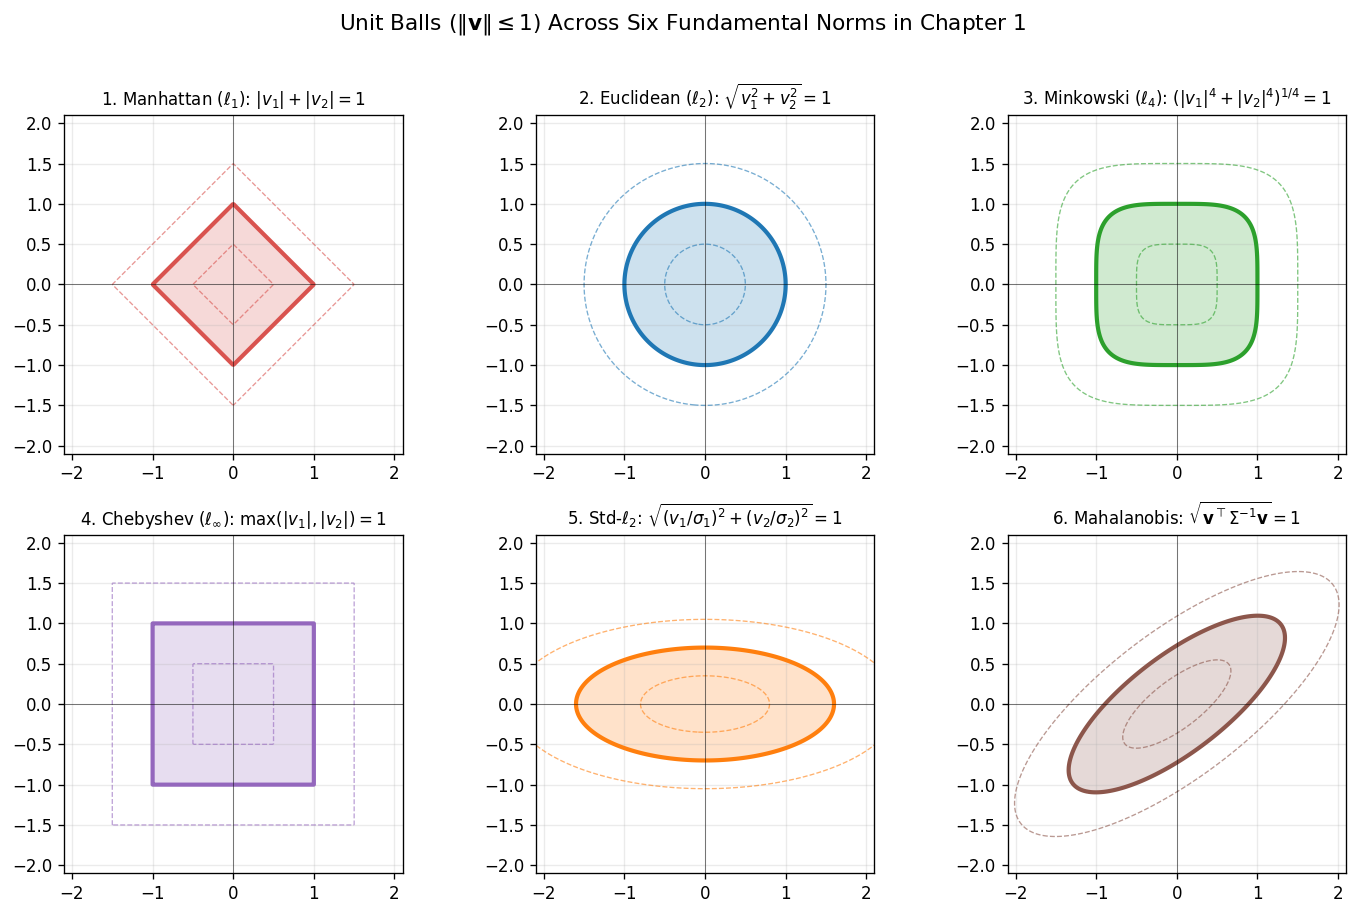

In [4]:
# Plot the unit balls {v in R^2 : ||v|| = 1} for all 6 norms
grid = np.linspace(-2.2, 2.2, 400)
V1, V2 = np.meshgrid(grid, grid)
pts = np.stack([V1, V2], axis=-1)

# Covariance matrix Sigma for Mahalanobis and scales sigma for Std-L2
Sigma = np.array([[1.8, 1.1],
                  [1.1, 1.2]])
Sigma_inv = np.linalg.inv(Sigma)
sigma_scales = np.array([1.6, 0.7])

norms_dict = {
    r"1. Manhattan ($\ell_1$): $|v_1| + |v_2| = 1$": np.abs(V1) + np.abs(V2),
    r"2. Euclidean ($\ell_2$): $\sqrt{v_1^2 + v_2^2} = 1$": np.sqrt(V1**2 + V2**2),
    r"3. Minkowski ($\ell_4$): $(|v_1|^4 + |v_2|^4)^{1/4} = 1$": (np.abs(V1)**4 + np.abs(V2)**4)**0.25,
    r"4. Chebyshev ($\ell_\infty$): $\max(|v_1|, |v_2|) = 1$": np.maximum(np.abs(V1), np.abs(V2)),
    r"5. Std-$\ell_2$: $\sqrt{(v_1/\sigma_1)^2 + (v_2/\sigma_2)^2} = 1$": np.sqrt((V1/sigma_scales[0])**2 + (V2/sigma_scales[1])**2),
    r"6. Mahalanobis: $\sqrt{\mathbf{v}^\top \Sigma^{-1}\mathbf{v}} = 1$": np.sqrt(
         np.einsum("...i,ij,...j->...", pts, Sigma_inv, pts)
    ),
}

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
colors = ["#d9534f", "#1f77b4", "#2ca02c", "#9467bd", "#ff7f0e", "#8c564b"]

for ax, (title, Z), col in zip(axes.ravel(), norms_dict.items(), colors):
    ax.contourf(V1, V2, Z, levels=[0, 1.0], colors=[col], alpha=0.22)
    ax.contour(V1, V2, Z, levels=[1.0], colors=[col], linewidths=2.5)
    ax.contour(V1, V2, Z, levels=[0.5, 1.5], colors=[col], linewidths=0.8, linestyles="--", alpha=0.6)
    ax.axhline(0, color="k", lw=0.6, alpha=0.5)
    ax.axvline(0, color="k", lw=0.6, alpha=0.5)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-2.1, 2.1)
    ax.set_ylim(-2.1, 2.1)

plt.suptitle("Unit Balls ($\\|\\mathbf{v}\\| \\leq 1$) Across Six Fundamental Norms in Chapter 1", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 2.2 Practical Application: Anomaly / OOD Detection with Mahalanobis vs. Euclidean Distance

Why does Chapter 1 emphasize **Mahalanobis distance** $\|\mathbf{x} - \boldsymbol{\mu}\|_M = \sqrt{(\mathbf{x}-\boldsymbol{\mu})^\top \Sigma^{-1} (\mathbf{x}-\boldsymbol{\mu})}$?

Suppose we monitor two strongly correlated features (e.g., server CPU load and power consumption). Consider two test points at the **exact same Euclidean distance** $\|\mathbf{x} - \boldsymbol{\mu}\|_2 = 3.0$ from the mean:
- **Point A** lies *along* the natural correlation axis (normal high-traffic behavior).
- **Point B** lies *orthogonal* to the correlation axis (e.g., high power consumption with low CPU load — a hardware fault or anomaly!).

Euclidean distance treats Point A and Point B identically, whereas Mahalanobis distance immediately flags Point B as a severe outlier.

Point A (Along correlation)      -> Euclidean: 2.979 | Mahalanobis: 1.561
Point B (Off-axis OOD Anomaly)   -> Euclidean: 3.007 | Mahalanobis: 6.957


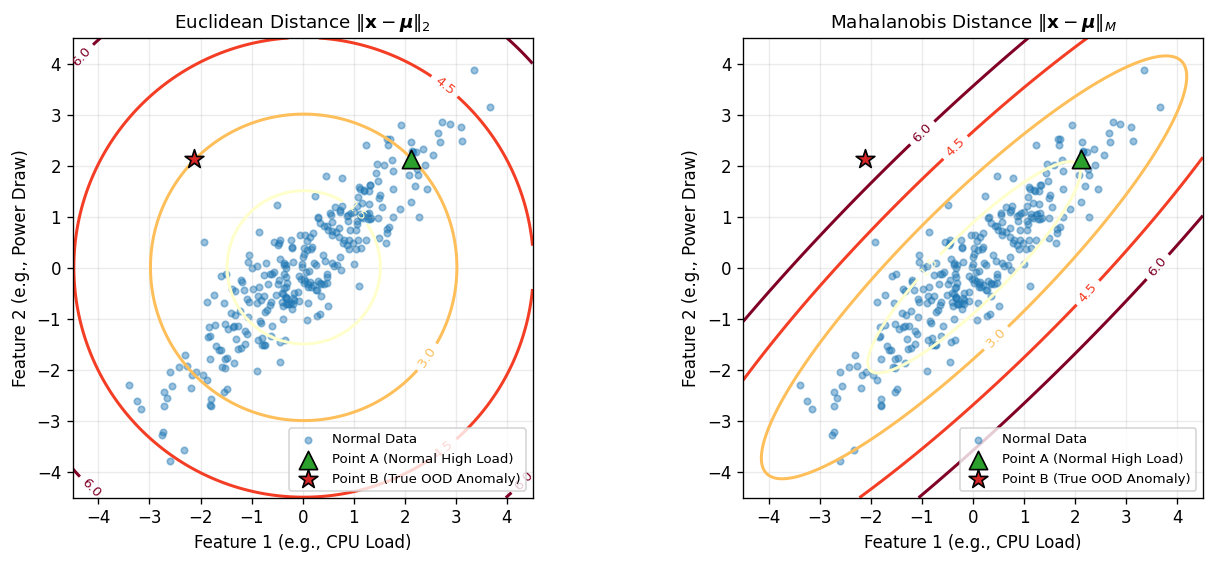

In [5]:
# Simulate correlated normal training data in R^2
cov_true = np.array([[2.0, 1.8],
                     [1.8, 2.0]])
mean_true = np.array([0.0, 0.0])
X_train_norm = np.random.multivariate_normal(mean_true, cov_true, size=300)

# Estimate sample mean and covariance
mu_hat = X_train_norm.mean(axis=0)
Sigma_hat = np.cov(X_train_norm, rowvar=False)
Sigma_hat_inv = np.linalg.inv(Sigma_hat)

# Construct two test points with the EXACT SAME Euclidean distance (3.0) from the origin:
# Point A: along the principal correlation diagonal [1, 1]/sqrt(2)
# Point B: orthogonal to the correlation diagonal [-1, 1]/sqrt(2)
dist_euclid = 3.0
pt_A = dist_euclid * np.array([1.0, 1.0]) / np.sqrt(2)     # In-distribution high load
pt_B = dist_euclid * np.array([-1.0, 1.0]) / np.sqrt(2)    # Out-of-distribution anomaly!

def mahalanobis_dist(x, mu, cov_inv):
    diff = x - mu
    return float(np.sqrt(diff.T @ cov_inv @ diff))

print(f"Point A (Along correlation)      -> Euclidean: {np.linalg.norm(pt_A - mu_hat):.3f} | Mahalanobis: {mahalanobis_dist(pt_A, mu_hat, Sigma_hat_inv):.3f}")
print(f"Point B (Off-axis OOD Anomaly)   -> Euclidean: {np.linalg.norm(pt_B - mu_hat):.3f} | Mahalanobis: {mahalanobis_dist(pt_B, mu_hat, Sigma_hat_inv):.3f}")

# Visualize Euclidean vs Mahalanobis contours
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
gx = np.linspace(-4.5, 4.5, 250)
GX, GY = np.meshgrid(gx, gx)
grid_pts = np.stack([GX - mu_hat[0], GY - mu_hat[1]], axis=-1)

Z_euclid = np.sqrt(grid_pts[..., 0]**2 + grid_pts[..., 1]**2)
Z_mahal = np.sqrt(np.einsum("...i,ij,...j->...", grid_pts, Sigma_hat_inv, grid_pts))

for ax, Z, name in zip(axes, [Z_euclid, Z_mahal], ["Euclidean Distance $\\|\\mathbf{x}-\\boldsymbol{\\mu}\\|_2$", "Mahalanobis Distance $\\|\\mathbf{x}-\\boldsymbol{\\mu}\\|_M$"]):
    ax.scatter(X_train_norm[:, 0], X_train_norm[:, 1], s=15, alpha=0.45, color="#1f77b4", label="Normal Data")
    cs = ax.contour(GX, GY, Z, levels=[1.5, 3.0, 4.5, 6.0], cmap="YlOrRd", linewidths=1.8)
    ax.clabel(cs, inline=True, fontsize=8, fmt="%.1f")
    ax.scatter(*pt_A, color="#2ca02c", s=120, marker="^", edgecolors="k", zorder=6, label="Point A (Normal High Load)")
    ax.scatter(*pt_B, color="#d62728", s=140, marker="*", edgecolors="k", zorder=6, label="Point B (True OOD Anomaly)")
    ax.set_aspect("equal")
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_title(name)
    ax.set_xlabel("Feature 1 (e.g., CPU Load)")
    ax.set_ylabel("Feature 2 (e.g., Power Draw)")
    ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

---
## Part 3: Hilbert vs. Banach Spaces in Practice — Ridge ($\ell_2$) vs. LASSO ($\ell_1$) Regularization

### 3.1 Why $(\mathbb{R}^d, \|\cdot\|_2)$ is a Hilbert Space while $(\mathbb{R}^d, \|\cdot\|_1)$ is Only a Banach Space

In Section *"Hilbert Space — Counterexample: $\ell_1$ Norm and LASSO Regularization"*, Chapter 1 shows that a norm is induced by an inner product **if and only if** it satisfies the **Parallelogram Law**:
$$\|\mathbf{u} + \mathbf{v}\|^2 + \|\mathbf{u} - \mathbf{v}\|^2 = 2\|\mathbf{u}\|^2 + 2\|\mathbf{v}\|^2 \quad \forall \mathbf{u}, \mathbf{v} \in \mathbb{R}^d$$

- **Ridge Regression ($\ell_2$ penalty)** operates in a **Hilbert space**:
  $$\min_{\boldsymbol{\theta}} \; \frac{1}{2N}\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \frac{\lambda}{2}\|\boldsymbol{\theta}\|_2^2$$
  Its unit ball is smooth and isotropic, yielding a closed-form inner-product solution and **dense** parameter shrinkage.
- **LASSO Regression ($\ell_1$ penalty)** operates in a **Banach space** (not a Hilbert space):
  $$\min_{\boldsymbol{\theta}} \; \frac{1}{2N}\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \lambda\|\boldsymbol{\theta}\|_1$$
  Because the $\ell_1$ unit ball has **sharp corners along the coordinate axes**, expanding loss contours almost always touch a corner first, driving irrelevant weights to **exact zero (sparsity)**!

In [6]:
# 1. Numerical Verification of the Parallelogram Law for L2 (Hilbert) vs L1 (Banach only)
u_test = np.array([1.0, 0.0])
v_test = np.array([0.0, 1.0])

for p_norm, space_type in [(2, "Hilbert Space (L2)"), (1, "Banach Space ONLY (L1)")]:
    lhs = np.linalg.norm(u_test + v_test, ord=p_norm)**2 + np.linalg.norm(u_test - v_test, ord=p_norm)**2
    rhs = 2 * (np.linalg.norm(u_test, ord=p_norm)**2 + np.linalg.norm(v_test, ord=p_norm)**2)
    print(f"{space_type:24s} -> LHS = {lhs:.2f}, RHS = {rhs:.2f} | Parallelogram Law Holds? {np.isclose(lhs, rhs)}")

Hilbert Space (L2)       -> LHS = 4.00, RHS = 4.00 | Parallelogram Law Holds? True
Banach Space ONLY (L1)   -> LHS = 8.00, RHS = 4.00 | Parallelogram Law Holds? False


### 3.2 Ordinary Training vs. $\ell_1$ (LASSO) & $\ell_2$ (Ridge) Regularization + Regularization Paths

Let us directly test and verify the central theorems from Chapter 1 regarding **Ordinary (Unregularized) Training**, **$\ell_2$ Regularization (Ridge / Hilbert space)**, and **$\ell_1$ Regularization (LASSO / Banach space)**:
- **Setup**: $N = 120$ samples ($80$ train, $40$ test), $d = 40$ features. Only **5 features** are true signals ($\boldsymbol{\theta}^* = [3.5, -2.8, 2.0, -1.5, 1.2, 0, \ldots, 0]^\top$), while the remaining **35 features are pure noise**!
- **1. Ordinary Training (Unregularized OLS)**:
  $$\min_{\boldsymbol{\theta}} \; \frac{1}{2N}\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 \implies \hat{\boldsymbol{\theta}}_{\text{OLS}} = (X^\top X)^{-1} X^\top \mathbf{y}$$
  With zero penalty on weight size, ordinary training fits spurious correlations in the $35$ noise features, resulting in non-zero noise weights and overfitting.
- **2. $\ell_2$ Regularization (Ridge Regression — Hilbert Space)**:
  $$\min_{\boldsymbol{\theta}} \; \frac{1}{2N}\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \frac{\lambda}{2}\|\boldsymbol{\theta}\|_2^2 \implies \hat{\boldsymbol{\theta}}_{\text{Ridge}}(\lambda) = (X^\top X + N\lambda I)^{-1} X^\top \mathbf{y}$$
  The smooth, isotropic $\ell_2$ unit ball introduces a radial contraction force that shrinks all coefficients smoothly toward zero. It suppresses noise variance, but **never drives weights to exact zero** (dense solution).
- **3. $\ell_1$ Regularization (LASSO — Banach Space)**:
  $$\min_{\boldsymbol{\theta}} \; \frac{1}{2N}\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \lambda \|\boldsymbol{\theta}\|_1$$
  Solved via **Proximal Gradient Descent (ISTA — Iterative Soft-Thresholding Algorithm)**:
  $$\boldsymbol{\theta}^{(k+1)} = \mathcal{S}_{\eta\lambda}\!\left(\boldsymbol{\theta}^{(k)} - \frac{\eta}{N} X^\top (X\boldsymbol{\theta}^{(k)} - \mathbf{y})\right), \quad [\mathcal{S}_{\tau}(\mathbf{z})]_i = \operatorname{sign}(z_i)\max(|z_i| - \tau, 0)$$
  The sharp corners of the $\ell_1$ diamond ball create an exact **dead-zone** $[-\tau, \tau]$ that snaps small noisy weights to **exact 0.0**, performing automatic feature selection and recovering the true 5 active signals!


In [7]:
# Generate synthetic high-dimensional sparse regression dataset
np.random.seed(42)
N_samples, d_features = 120, 40
X_raw = np.random.randn(N_samples, d_features)
# Standardize features (Z-score normalization from Chapter 1)
X_data = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)

# True sparse weight vector: only first 5 features are non-zero!
theta_true = np.zeros(d_features)
active_indices = [0, 1, 2, 3, 4]
theta_true[active_indices] = [3.5, -2.8, 2.0, -1.5, 1.2]

# Generate noisy targets y = X @ theta_true + noise
y_data = X_data @ theta_true + 0.5 * np.random.randn(N_samples)

# Split into train (80) and test (40)
X_tr, X_te = X_data[:80], X_data[80:]
y_tr, y_te = y_data[:80], y_data[80:]

# --- 1. From-Scratch Ridge Solver ---
def fit_ridge_scratch(X, y, lam):
    N, d = X.shape
    return np.linalg.solve(X.T @ X + N * lam * np.eye(d), X.T @ y)

# --- 2. From-Scratch LASSO Solver (ISTA Soft-Thresholding) ---
def soft_threshold(z, tau):
    return np.sign(z) * np.maximum(np.abs(z) - tau, 0.0)

def fit_lasso_ista(X, y, lam, max_iter=2000, tol=1e-7):
    N, d = X.shape
    # Lipschitz constant of (1/N) X^T X is largest eigenvalue / N
    L = np.linalg.norm(X, ord=2) ** 2 / N
    eta = 1.0 / L
    theta = np.zeros(d)
    for _ in range(max_iter):
        grad = (X.T @ (X @ theta - y)) / N
        theta_next = soft_threshold(theta - eta * grad, eta * lam)
        if np.linalg.norm(theta_next - theta) < tol:
            theta = theta_next
            break
        theta = theta_next
    return theta

# Fit Ordinary OLS, Ridge (L2), and LASSO (L1)
lam_demo = 0.18
theta_ols = fit_ridge_scratch(X_tr, y_tr, lam=1e-12)
theta_ridge = fit_ridge_scratch(X_tr, y_tr, lam=lam_demo)
theta_lasso = fit_lasso_ista(X_tr, y_tr, lam=lam_demo)

# Verify against scikit-learn Lasso
sk_lasso = Lasso(alpha=lam_demo, fit_intercept=False, max_iter=5000).fit(X_tr, y_tr)
print(f"Max difference between our ISTA LASSO and sklearn Lasso: {np.max(np.abs(theta_lasso - sk_lasso.coef_)):.2e}")

# Compare Ordinary Training vs. L2 vs. L1 Regularization
noise_idx = np.arange(5, d_features)
print("-" * 105)
print(f"{'Training Paradigm':36s} | {'Test MSE':8s} | {'Exact Zeros':16s} | {'||w_noise||_2':14s} | {'Max Noise |w|':12s}")
print("-" * 105)
models_comp = [
    ("Ordinary Training (Unregularized OLS)", theta_ols),
    ("L2 Regularization (Ridge, Hilbert)", theta_ridge),
    ("L1 Regularization (LASSO, Banach)", theta_lasso)
]
for name, w in models_comp:
    test_mse = np.mean((X_te @ w - y_te) ** 2)
    num_zeros = np.sum(np.abs(w) < 1e-4)
    noise_l2 = np.linalg.norm(w[noise_idx])
    noise_max = np.max(np.abs(w[noise_idx]))
    print(f"{name:36s} | {test_mse:8.4f} | {num_zeros:2d} / {d_features} (True: 35)   | {noise_l2:14.4f} | {noise_max:12.4f}")
print("-" * 105)


Max difference between our ISTA LASSO and sklearn Lasso: 5.65e-06
---------------------------------------------------------------------------------------------------------
Training Paradigm                    | Test MSE | Exact Zeros      | ||w_noise||_2  | Max Noise |w|
---------------------------------------------------------------------------------------------------------
Ordinary Training (Unregularized OLS) |   0.4424 |  0 / 40 (True: 35)   |         0.4505 |       0.1928
L2 Regularization (Ridge, Hilbert)   |   3.2856 |  0 / 40 (True: 35)   |         0.9611 |       0.3774
L1 Regularization (LASSO, Banach)    |   0.3683 | 35 / 40 (True: 35)   |         0.0000 |       0.0000
---------------------------------------------------------------------------------------------------------


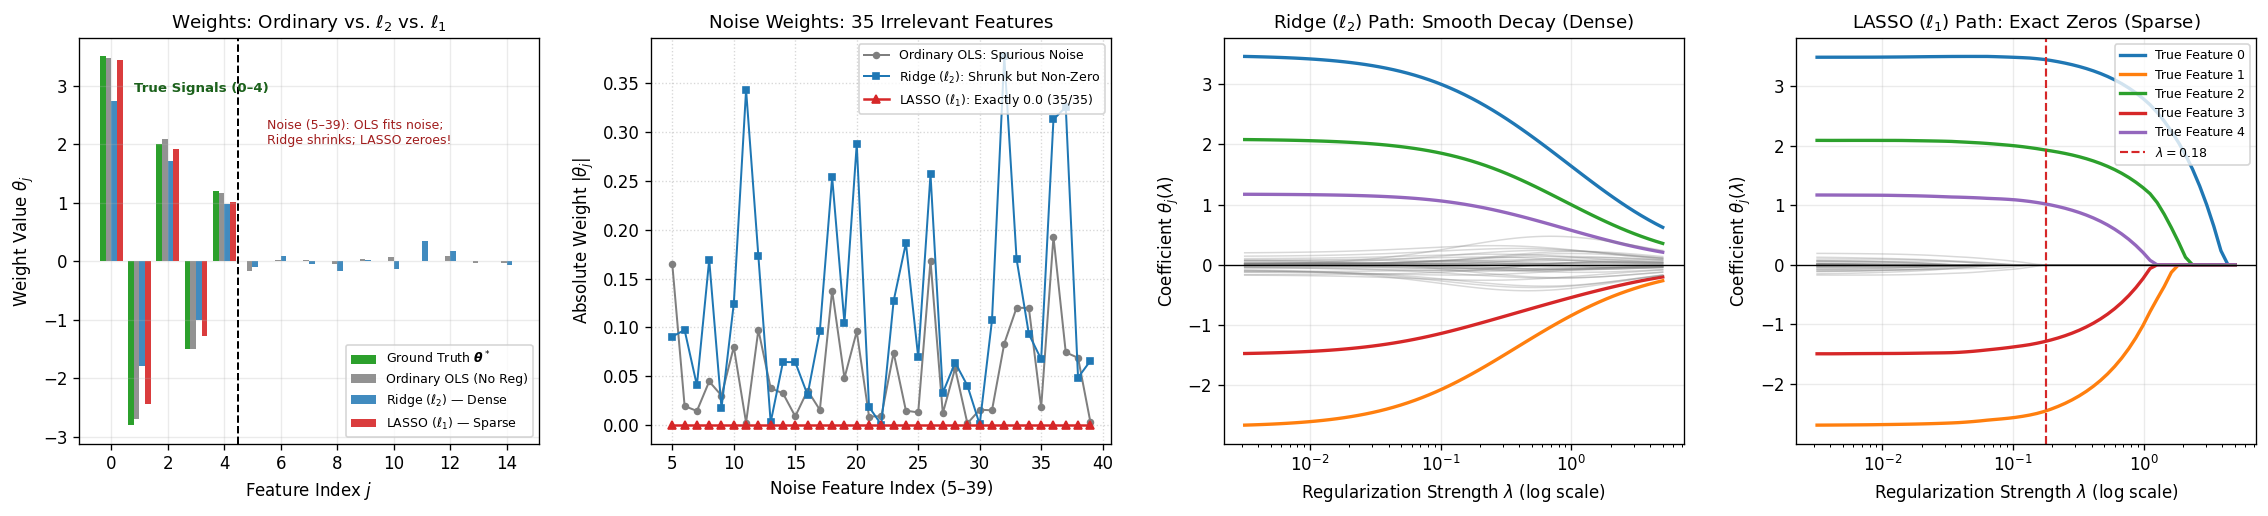

In [8]:
# Compute full Regularization Paths across a grid of lambda values
lambdas = np.logspace(-2.5, 0.7, 60)
ridge_path = np.array([fit_ridge_scratch(X_tr, y_tr, lam) for lam in lambdas])
lasso_path = np.array([fit_lasso_ista(X_tr, y_tr, lam) for lam in lambdas])

fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))

# Panel 1: Learned Weights: Ground Truth vs. Ordinary OLS vs. Ridge vs. LASSO
ax = axes[0]
idx = np.arange(15)  # Plot first 15 features (0..4 true signals, 5..14 noise)
width = 0.20
ax.bar(idx - 1.5*width, theta_true[:15], width=width, color="#2ca02c", label=r"Ground Truth $\boldsymbol{\theta}^*$")
ax.bar(idx - 0.5*width, theta_ols[:15], width=width, color="#7f7f7f", alpha=0.85, label="Ordinary OLS (No Reg)")
ax.bar(idx + 0.5*width, theta_ridge[:15], width=width, color="#1f77b4", alpha=0.85, label=r"Ridge ($\ell_2$) — Dense")
ax.bar(idx + 1.5*width, theta_lasso[:15], width=width, color="#d62728", alpha=0.9, label=r"LASSO ($\ell_1$) — Sparse")
ax.axvline(4.5, color="k", ls="--", lw=1.2)
ax.text(0.8, 2.9, "True Signals (0–4)", fontsize=8, fontweight="bold", color="#1b611b")
ax.text(5.5, 2.0, "Noise (5–39): OLS fits noise;\nRidge shrinks; LASSO zeroes!", fontsize=7.5, color="#a11d1d")
ax.set_xlabel("Feature Index $j$")
ax.set_ylabel(r"Weight Value $\theta_j$")
ax.set_title(r"Weights: Ordinary vs. $\ell_2$ vs. $\ell_1$")
ax.legend(fontsize=7.5, loc="lower right")

# Panel 2: Weight Magnitudes on 35 Pure Noise Features (5–39)
ax = axes[1]
noise_idx = np.arange(5, 40)
ax.plot(noise_idx, np.abs(theta_ols[noise_idx]), "o-", color="#7f7f7f", ms=3.5, lw=1.2, label="Ordinary OLS: Spurious Noise")
ax.plot(noise_idx, np.abs(theta_ridge[noise_idx]), "s-", color="#1f77b4", ms=3.5, lw=1.2, label=r"Ridge ($\ell_2$): Shrunk but Non-Zero")
ax.plot(noise_idx, np.abs(theta_lasso[noise_idx]), "^-", color="#d62728", ms=4.5, lw=1.5, label=r"LASSO ($\ell_1$): Exactly 0.0 (35/35)")
ax.set_xlabel("Noise Feature Index (5–39)")
ax.set_ylabel(r"Absolute Weight $|\theta_j|$")
ax.set_title("Noise Weights: 35 Irrelevant Features")
ax.legend(fontsize=7.5, loc="upper right")
ax.grid(True, ls=":", alpha=0.5)

# Panel 3: Ridge Regularization Path (Smooth Asymptotic Decay)
ax = axes[2]
for j in range(d_features):
    if j in active_indices:
        ax.plot(lambdas, ridge_path[:, j], lw=2.0, label=f"True Feature {j}" if j < 3 else None)
    else:
        ax.plot(lambdas, ridge_path[:, j], color="gray", alpha=0.3, lw=0.9)
ax.set_xscale("log")
ax.set_xlabel(r"Regularization Strength $\lambda$ (log scale)")
ax.set_ylabel(r"Coefficient $\theta_j(\lambda)$")
ax.set_title(r"Ridge ($\ell_2$) Path: Smooth Decay (Dense)")
ax.axhline(0, color="k", lw=0.8)

# Panel 4: LASSO Regularization Path (Piecewise-Linear Exact Zeros)
ax = axes[3]
for j in range(d_features):
    if j in active_indices:
        ax.plot(lambdas, lasso_path[:, j], lw=2.0, label=f"True Feature {j}")
    else:
        ax.plot(lambdas, lasso_path[:, j], color="gray", alpha=0.3, lw=0.9)
ax.axvline(lam_demo, color="#d62728", ls="--", lw=1.3, label=rf"$\lambda = {lam_demo}$")
ax.set_xscale("log")
ax.set_xlabel(r"Regularization Strength $\lambda$ (log scale)")
ax.set_ylabel(r"Coefficient $\theta_j(\lambda)$")
ax.set_title(r"LASSO ($\ell_1$) Path: Exact Zeros (Sparse)")
ax.axhline(0, color="k", lw=0.8)
ax.legend(fontsize=7.5, loc="upper right")

plt.tight_layout()
plt.show()


---
## Part 4: Banach Space Completeness, Cauchy Sequences & Weight Decay in Deep Learning

### 4.1 Weight Matrix Space as a Banach Space & The Weight Decay "Quadratic Bowl"

In Section *"Example: Weight Matrix Space as a Banach Space"*, Chapter 1 models neural network training as a sequence of weight matrices $\{\mathbf{W}_k\}_{k=0}^\infty$ in the Banach space $(\mathbb{R}^{m \times n}, \|\cdot\|_F)$ equipped with the Frobenius norm $\|\mathbf{W}\|_F = \sqrt{\sum_{i,j} W_{ij}^2}$.

Consider minimizing the quadratic loss around $\mathbf{W}^* = \begin{bmatrix} 1.0 & -2.0 \\ 0.5 & 3.0 \end{bmatrix}$ starting from $\mathbf{W}_0 = \begin{bmatrix} 5.0 & 5.0 \\ -4.0 & -3.0 \end{bmatrix}$:
- **Without Weight Decay ($\lambda = 0$)**:
  $$\mathcal{L}(\mathbf{W}) = \|\mathbf{W} - \mathbf{W}^*\|_F^2 \implies \mathbf{W}_{k+1} = \mathbf{W}_k - 2\eta(\mathbf{W}_k - \mathbf{W}^*)$$
  The sequence $\{\mathbf{W}_k\}$ is a **Cauchy sequence** ($\|\mathbf{W}_{k+1} - \mathbf{W}_k\|_F \to 0$) and converges to $\mathbf{W}^*$.
- **With $\ell_2$ Weight Decay ($\lambda > 0$)**:
  $$\mathcal{L}_{\text{WD}}(\mathbf{W}) = \|\mathbf{W} - \mathbf{W}^*\|_F^2 + \frac{\lambda}{2}\|\mathbf{W}\|_F^2 \implies \mathbf{W}_{k+1} = \mathbf{W}_k - 2\eta(\mathbf{W}_k - \mathbf{W}^*) - \eta\lambda \mathbf{W}_k$$
  Weight decay adds a radial potential field $V(\mathbf{W}) = \frac{\lambda}{2}\|\mathbf{W}\|_F^2$ ("quadratic bowl") that pulls the converged limit inward toward the origin:
  $$\mathbf{W}_{\text{opt}} = \frac{2}{2 + \lambda} \mathbf{W}^*$$

### 4.2 Counterexample: Stochastic Gradient Noise — Loss Decreases but Sequence is NOT Cauchy!

When training with minibatch SGD under a **constant learning rate** $\eta$ and stochastic gradient noise $\boldsymbol{\epsilon}_k$:
$$\mathbf{W}_{k+1} = \mathbf{W}_k - \eta\big(2(\mathbf{W}_k - \mathbf{W}^*) + \boldsymbol{\epsilon}_k\big)$$
Even after the loss plateaus near its minimum, consecutive step sizes $\|\mathbf{W}_{k+1} - \mathbf{W}_k\|_F \approx \eta \|\boldsymbol{\epsilon}_k\|_F \not\to 0$. Thus $\{\mathbf{W}_k\}$ is **not Cauchy** and wanders perpetually in a noise ball around $\mathbf{W}^*$ unless we decay the learning rate ($\eta_k \to 0$).

Converged W (Standard GD):
 [[ 1.  -2. ]
 [ 0.5  3. ]]
Converged W (With Weight Decay lambda=0.5):
 [[ 0.8 -1.6]
 [ 0.4  2.4]]
Theoretical Shifted Optimum W_opt = (2/(2+lambda))*W^*:
 [[ 0.8 -1.6]
 [ 0.4  2.4]]
Max error between converged WD matrix and W_opt: 1.17e-07


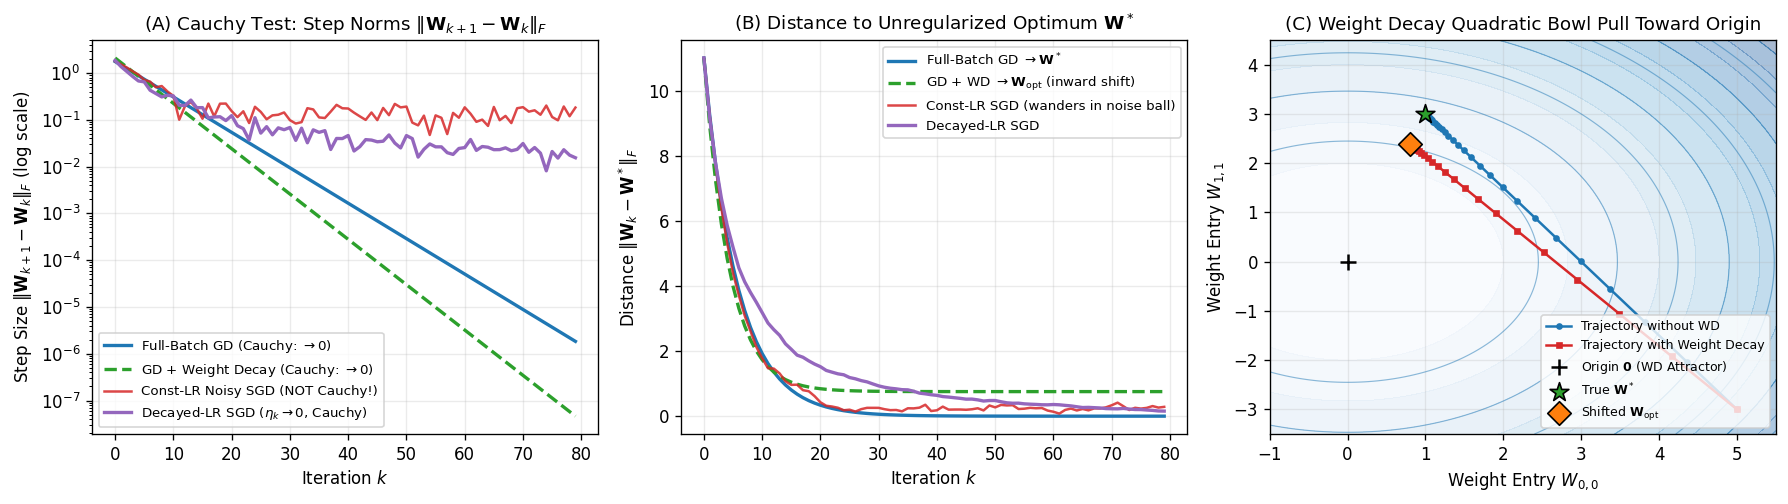

In [9]:
# Reproduce Chapter 1's exact 2x2 Weight Matrix Banach Space trajectories
W_star = np.array([[1.0, -2.0],
                   [0.5,  3.0]])
W_init = np.array([[ 5.0,  5.0],
                   [-4.0, -3.0]])

eta = 0.08
lam_wd = 0.5
steps = 80
W_opt_theoretical = (2.0 / (2.0 + lam_wd)) * W_star

def run_matrix_optimization(mode="clean_gd"):
    W = W_init.copy()
    traj = [W.copy()]
    step_diffs = []
    dist_to_star = []
    losses = []
    for k in range(steps):
        lr = eta / (1.0 + 0.08 * k) if mode == "sgd_decayed" else eta
        grad = 2.0 * (W - W_star)
        if mode in ("sgd_const", "sgd_decayed"):
            grad = grad + np.random.randn(*W.shape) * 0.9  # Minibatch gradient noise
        if mode == "weight_decay":
            W_next = W - lr * grad - lr * lam_wd * W
        else:
            W_next = W - lr * grad
        losses.append(np.linalg.norm(W - W_star, "fro")**2)
        step_diffs.append(np.linalg.norm(W_next - W, "fro"))
        dist_to_star.append(np.linalg.norm(W - W_star, "fro"))
        W = W_next
        traj.append(W.copy())
    return np.array(traj), np.array(losses), np.array(step_diffs), np.array(dist_to_star)

np.random.seed(7)
traj_gd, loss_gd, diff_gd, dist_gd = run_matrix_optimization("clean_gd")
traj_wd, loss_wd, diff_wd, dist_wd = run_matrix_optimization("weight_decay")
traj_noisy, loss_noisy, diff_noisy, dist_noisy = run_matrix_optimization("sgd_const")
traj_decay, loss_decay, diff_decay, dist_decay = run_matrix_optimization("sgd_decayed")

print("Converged W (Standard GD):\n", traj_gd[-1].round(4))
print("Converged W (With Weight Decay lambda=0.5):\n", traj_wd[-1].round(4))
print("Theoretical Shifted Optimum W_opt = (2/(2+lambda))*W^*:\n", W_opt_theoretical.round(4))
print(f"Max error between converged WD matrix and W_opt: {np.max(np.abs(traj_wd[-1] - W_opt_theoretical)):.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Plot A: Consecutive Parameter Updates ||W_{k+1} - W_k||_F (Cauchy Criterion)
ax = axes[0]
ax.plot(diff_gd, lw=2, color="#1f77b4", label="Full-Batch GD (Cauchy: $\\to 0$)")
ax.plot(diff_wd, lw=2, color="#2ca02c", ls="--", label="GD + Weight Decay (Cauchy: $\\to 0$)")
ax.plot(diff_noisy, lw=1.5, color="#d62728", alpha=0.85, label="Const-LR Noisy SGD (NOT Cauchy!)")
ax.plot(diff_decay, lw=2, color="#9467bd", label="Decayed-LR SGD ($\\eta_k \\to 0$, Cauchy)")
ax.set_yscale("log")
ax.set_xlabel("Iteration $k$")
ax.set_ylabel("Step Size $\\|\\mathbf{W}_{k+1} - \\mathbf{W}_k\\|_F$ (log scale)")
ax.set_title("(A) Cauchy Test: Step Norms $\\|\\mathbf{W}_{k+1} - \\mathbf{W}_k\\|_F$")
ax.legend(fontsize=8)

# Plot B: Distance to Optimum ||W_k - W^*||_F
ax = axes[1]
ax.plot(dist_gd, lw=2, color="#1f77b4", label="Full-Batch GD $\\to \\mathbf{W}^*$")
ax.plot(dist_wd, lw=2, color="#2ca02c", ls="--", label="GD + WD $\\to \\mathbf{W}_{\\mathrm{opt}}$ (inward shift)")
ax.plot(dist_noisy, lw=1.5, color="#d62728", alpha=0.85, label="Const-LR SGD (wanders in noise ball)")
ax.plot(dist_decay, lw=2, color="#9467bd", label="Decayed-LR SGD")
ax.set_xlabel("Iteration $k$")
ax.set_ylabel("Distance $\\|\\mathbf{W}_k - \\mathbf{W}^*\\|_F$")
ax.set_title("(B) Distance to Unregularized Optimum $\\mathbf{W}^*$")
ax.legend(fontsize=8)

# Plot C: 2D Slice of Weight Space (W_{0,0}, W_{1,1}) Showing Weight Decay Radial Pull
ax = axes[2]
w00 = np.linspace(-1.0, 5.5, 150)
w11 = np.linspace(-3.5, 4.5, 150)
G00, G11 = np.meshgrid(w00, w11)
pot_bowl = 0.5 * lam_wd * (G00**2 + G11**2)
ax.contourf(G00, G11, pot_bowl, levels=12, cmap="Blues", alpha=0.35)
ax.contour(G00, G11, pot_bowl, levels=8, colors="#1f77b4", linewidths=0.7, alpha=0.5)

ax.plot(traj_gd[:, 0, 0], traj_gd[:, 1, 1], "o-", ms=3, color="#1f77b4", label="Trajectory without WD")
ax.plot(traj_wd[:, 0, 0], traj_wd[:, 1, 1], "s-", ms=3, color="#d62728", label="Trajectory with Weight Decay")
ax.scatter([0], [0], color="k", s=90, marker="+", zorder=6, label="Origin $\\mathbf{0}$ (WD Attractor)")
ax.scatter([W_star[0, 0]], [W_star[1, 1]], color="#2ca02c", s=140, marker="*", edgecolors="k", zorder=6, label="True $\\mathbf{W}^*$")
ax.scatter([W_opt_theoretical[0, 0]], [W_opt_theoretical[1, 1]], color="#ff7f0e", s=100, marker="D", edgecolors="k", zorder=6, label="Shifted $\\mathbf{W}_{\\mathrm{opt}}$")
ax.set_xlabel("Weight Entry $W_{0,0}$")
ax.set_ylabel("Weight Entry $W_{1,1}$")
ax.set_title("(C) Weight Decay Quadratic Bowl Pull Toward Origin")
ax.legend(fontsize=7.5, loc="lower right")

plt.tight_layout()
plt.show()

### 4.3 PyTorch Deep Learning Practical: Ordinary Training vs. $\ell_1$ Sparsity, $\ell_2$ Weight Decay & `AdamW`

In Section *"Weight decay as a geometric intervention"*, Chapter 1 highlights how regularizations shape parameter space in modern deep learning:
1. **Ordinary Training (No Regularization, $\lambda = 0$)**:
   Minimizes pure training MSE. With $4,353$ parameters in an overparameterized MLP fitting only $22$ noisy data points, unconstrained gradient descent memorizes noise, causing weights to blow up and producing wild oscillations between training points.
2. **$\ell_1$ Regularization (L1 Penalty — Banach Space)**:
   Adds $\lambda_1 \sum_{i} |w_i|$ to the loss. In high-dimensional neural network parameter space, the $\ell_1$ geometry drives redundant weights into zero dead-zones, producing **sparse networks** (>99% weights near zero) and naturally controlling model complexity.
3. **$\ell_2$ Regularization (Coupled L2 Weight Decay)**:
   Adds $\frac{\lambda}{2}\|\mathbf{W}\|_F^2$ to the loss. In standard `Adam`, adding $\lambda \boldsymbol{\theta}_k$ inside the gradient before dividing by the adaptive preconditioner $\sqrt{\mathbf{v}_k} + \epsilon$ creates a geometric distortion: parameters with large historical gradients receive weaker decay.
4. **AdamW (Decoupled Weight Decay)**:
   Separates the two geometries: computes the adaptive preconditioner on the pure objective gradient, and applies weight decay $-\eta\lambda\boldsymbol{\theta}_k$ directly as a Euclidean contraction step.

Let us train our overparameterized MLP across all four regimes and directly compare:
- Learned function curves (overfitting vs. regularized smooth generalization)
- Test MSE evolution during training
- Weight Frobenius norm and parameter sparsity (near-zero parameter percentage)


In [10]:
# Generate a small noisy 1D regression dataset prone to overfitting
torch.manual_seed(42)
np.random.seed(42)

n_train_dl = 22
x_train_dl = np.sort(np.random.uniform(-2.0, 2.0, n_train_dl))
y_true_fn = lambda x: np.sin(1.8 * x) + 0.3 * x
y_train_dl = y_true_fn(x_train_dl) + 0.38 * np.random.randn(n_train_dl)

x_grid_dl = np.linspace(-2.2, 2.2, 200)
y_clean_dl = y_true_fn(x_grid_dl)

X_tr_t = torch.tensor(x_train_dl, dtype=torch.float32).unsqueeze(1)
y_tr_t = torch.tensor(y_train_dl, dtype=torch.float32).unsqueeze(1)
X_grid_t = torch.tensor(x_grid_dl, dtype=torch.float32).unsqueeze(1)

class OverparameterizedMLP(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 1)
        )
    def forward(self, x):
        return self.net(x)

def total_frobenius_norm(model):
    return float(np.sqrt(sum(torch.sum(p.detach()**2).item() for p in model.parameters())))

def count_near_zeros(model, threshold=1e-2):
    total = sum(p.numel() for p in model.parameters())
    zeros = sum(torch.sum(torch.abs(p.detach()) < threshold).item() for p in model.parameters())
    return int(zeros), int(total)

def train_mlp(mode, epochs=1200):
    torch.manual_seed(10)
    model = OverparameterizedMLP(hidden=64)
    criterion = nn.MSELoss()
    
    l1_lambda = 0.003
    if mode == "Ordinary (No WD)":
        opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0)
    elif mode == "L1 Regularization":
        opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0)
    elif mode == "Coupled L2 Decay":
        opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.02)
    elif mode == "AdamW (Decoupled WD)":
        opt = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.8)
    
    val_losses = []
    f_norms = []
    for _ in range(epochs):
        opt.zero_grad()
        pred = model(X_tr_t)
        loss = criterion(pred, y_tr_t)
        if mode == "L1 Regularization":
            l1_loss = sum(p.abs().sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_loss
        loss.backward()
        opt.step()
        
        with torch.no_grad():
            pred_grid = model(X_grid_t).squeeze(1).numpy()
            val_mse = float(np.mean((pred_grid - y_clean_dl) ** 2))
            val_losses.append(val_mse)
            f_norms.append(total_frobenius_norm(model))
            
    with torch.no_grad():
        final_curve = model(X_grid_t).squeeze(1).numpy()
        train_mse = float(criterion(model(X_tr_t), y_tr_t).item())
        zeros, total = count_near_zeros(model, 1e-2)
    return final_curve, train_mse, val_losses[-1], val_losses, f_norms, zeros, total

modes = ["Ordinary (No WD)", "L1 Regularization", "Coupled L2 Decay", "AdamW (Decoupled WD)"]
results = {}
print("-" * 105)
print(f"{'Training Regime':26s} | {'Train MSE':9s} | {'True-Fn MSE':11s} | {'||W||_F':9s} | {'Near Zeros (<0.01)':20s} | {'Sparsity':8s}")
print("-" * 105)
for m in modes:
    curve, tr_mse, te_mse, v_hist, fn_hist, zeros, total = train_mlp(m)
    results[m] = (curve, tr_mse, te_mse, v_hist, fn_hist, zeros, total)
    sparsity = (zeros / total) * 100.0
    print(f"{m:26s} | {tr_mse:9.4f} | {te_mse:11.4f} | {fn_hist[-1]:9.2f} | {zeros:5d} / {total:5d}       | {sparsity:6.1f}%")
print("-" * 105)


---------------------------------------------------------------------------------------------------------
Training Regime            | Train MSE | True-Fn MSE | ||W||_F   | Near Zeros (<0.01)   | Sparsity
---------------------------------------------------------------------------------------------------------
Ordinary (No WD)           |    0.0042 |      0.4024 |     22.65 |   215 /  4353       |    4.9%
L1 Regularization          |    0.1105 |      0.0527 |      3.75 |  4343 /  4353       |   99.8%
Coupled L2 Decay           |    0.1155 |      0.0424 |      3.05 |   188 /  4353       |    4.3%
AdamW (Decoupled WD)       |    0.0811 |      0.0843 |      9.59 |  1864 /  4353       |   42.8%
---------------------------------------------------------------------------------------------------------


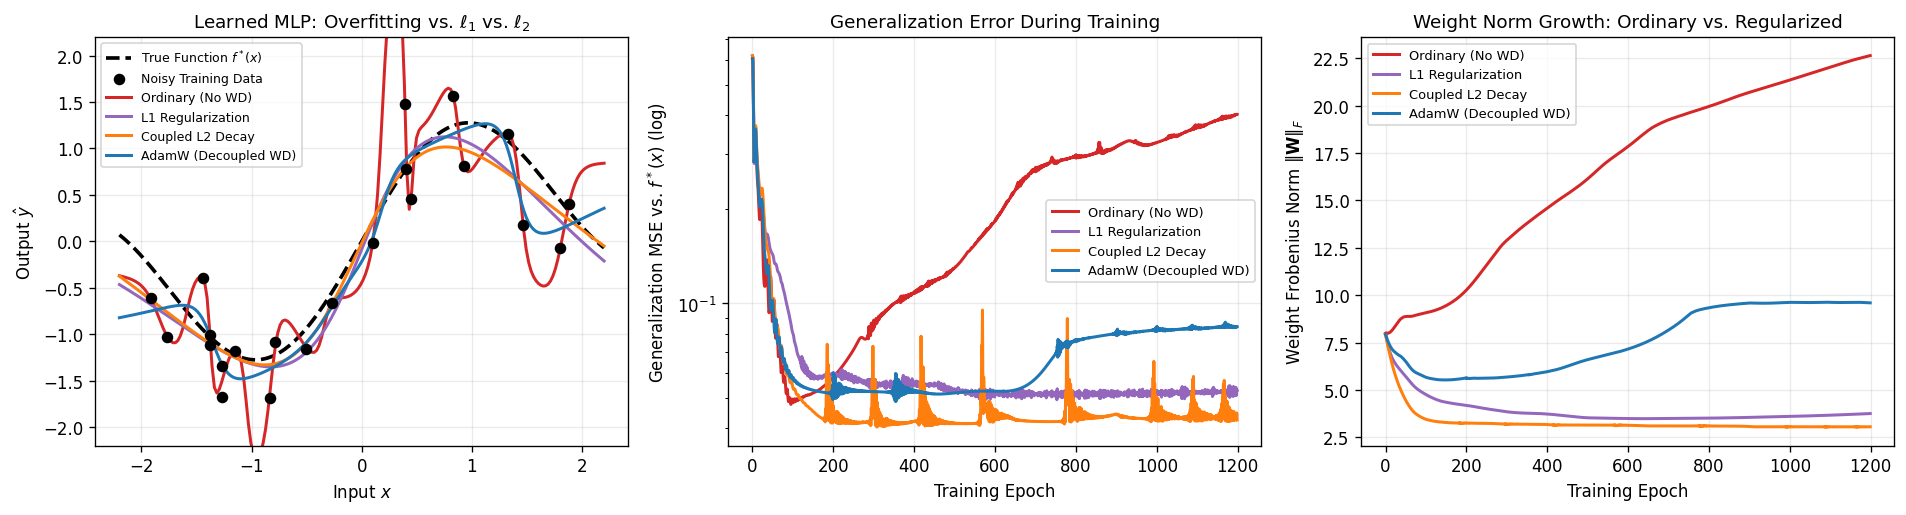

In [11]:
# Visualize the learned functions, generalization error, and Frobenius norm / sparsity trajectories
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
colors_dl = {
    "Ordinary (No WD)": "#d62728",
    "L1 Regularization": "#9467bd",
    "Coupled L2 Decay": "#ff7f0e",
    "AdamW (Decoupled WD)": "#1f77b4"
}

# Panel 1: Fitted curves vs True Function
ax = axes[0]
ax.plot(x_grid_dl, y_clean_dl, "k--", lw=2.2, label=r"True Function $f^*(x)$")
ax.scatter(x_train_dl, y_train_dl, color="k", s=35, zorder=5, label="Noisy Training Data")
for m in modes:
    ax.plot(x_grid_dl, results[m][0], lw=1.8, color=colors_dl[m], label=m)
ax.set_ylim(-2.2, 2.2)
ax.set_xlabel("Input $x$")
ax.set_ylabel(r"Output $\hat{y}$")
ax.set_title(r"Learned MLP: Overfitting vs. $\ell_1$ vs. $\ell_2$")
ax.legend(fontsize=7.5, loc="upper left")

# Panel 2: True-Function Generalization MSE over Epochs
ax = axes[1]
for m in modes:
    ax.plot(results[m][3], lw=1.8, color=colors_dl[m], label=m)
ax.set_yscale("log")
ax.set_xlabel("Training Epoch")
ax.set_ylabel(r"Generalization MSE vs. $f^*(x)$ (log)")
ax.set_title("Generalization Error During Training")
ax.legend(fontsize=7.8)

# Panel 3: Network Weight Frobenius Norm ||W||_F over Epochs
ax = axes[2]
for m in modes:
    ax.plot(results[m][4], lw=1.8, color=colors_dl[m], label=m)
ax.set_xlabel("Training Epoch")
ax.set_ylabel(r"Weight Frobenius Norm $\|\mathbf{W}\|_F$")
ax.set_title("Weight Norm Growth: Ordinary vs. Regularized")
ax.legend(fontsize=7.8)

plt.tight_layout()
plt.show()


---
## Part 5: Gram–Schmidt Orthonormalization & Scaled Dot-Product Attention in Hilbert Space

### 5.1 Gram–Schmidt Algorithm for Orthonormal Basis Construction

Given linearly independent vectors $\{\mathbf{v}_0, \ldots, \mathbf{v}_{k-1}\} \subset \mathbb{R}^d$, the **Gram–Schmidt algorithm** recursively subtracts projections onto previously constructed unit vectors:
$$\mathbf{u}_j = \mathbf{v}_j - \sum_{i=0}^{j-1} \langle \mathbf{v}_j, \mathbf{q}_i \rangle \mathbf{q}_i, \qquad \mathbf{q}_j = \frac{\mathbf{u}_j}{\|\mathbf{u}_j\|_2}$$
producing an orthonormal basis $Q = [\mathbf{q}_0, \ldots, \mathbf{q}_{k-1}]$ satisfying $Q^\top Q = I_k$.

### 5.2 Transformer Scaled Dot-Product Attention in Hilbert Space

In Section *"Example: Transformer Attention in Hilbert Space"*, token representations $\mathbf{x}_i \in \mathbb{R}^d$ are mapped to queries, keys, and values ($Q = XW_Q, K = XW_K, V = XW_V$), and attention computes:
$$\text{Attention}(Q, K, V) = \underbrace{\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)}_{A \text{ (row-stochastic)}} V$$
Why do we divide the inner products $\langle \mathbf{q}_i, \mathbf{k}_j \rangle$ by $\sqrt{d_k}$?
- If components of $\mathbf{q}, \mathbf{k} \in \mathbb{R}^{d_k}$ have zero mean and unit variance, then $\operatorname{Var}(\mathbf{q}^\top \mathbf{k}) = d_k$, so $\|\mathbf{q}^\top \mathbf{k}\| \sim \mathcal{O}(\sqrt{d_k})$.
- For large $d_k$, unscaled dot products push softmax into saturation (one weight $\approx 1$, all others $\approx 0$), causing **vanishing softmax gradients**. Dividing by $\sqrt{d_k}$ restores unit variance!

Gram-Schmidt Orthonormal Basis Q (4x3):
 [[ 0.8165 -0.255  -0.4809]
 [ 0.4082  0.8288  0.3306]
 [ 0.     -0.3825  0.5109]
 [ 0.4082 -0.3188  0.6312]]
Verification Q^T Q == I_3:
 [[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]


<>:59: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3992994/465565609.py:59: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")
/tmp/ipykernel_3992994/465565609.py:67: SyntaxWarning: invalid escape sequence '\l'
  axes[1].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")


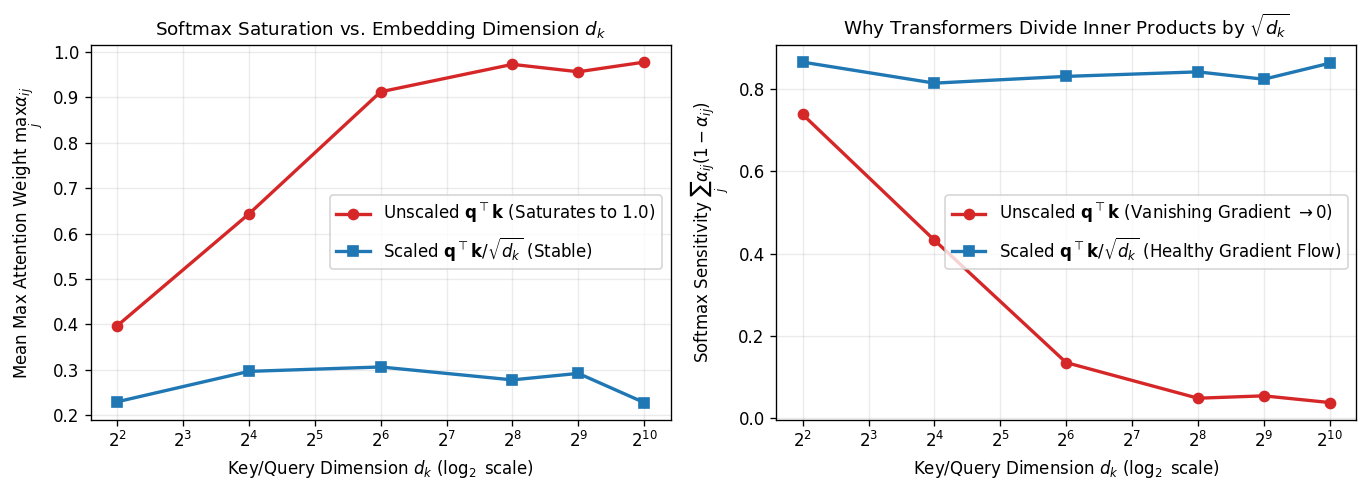

In [12]:
# 1. Gram-Schmidt Orthonormalization From Scratch
def gram_schmidt(V):
    # Orthonormalize columns of V (d x k) using Gram-Schmidt
    d, k = V.shape
    Q = np.zeros((d, k))
    for j in range(k):
        u = V[:, j].copy()
        for i in range(j):
            u -= np.dot(V[:, j], Q[:, i]) * Q[:, i]
        norm_u = np.linalg.norm(u)
        if norm_u < 1e-12:
            raise ValueError(f"Column {j} is linearly dependent on previous columns.")
        Q[:, j] = u / norm_u
    return Q

V_basis = np.array([[2.0,  1.0, 0.0],
                    [1.0,  3.0, 1.0],
                    [0.0, -1.0, 2.0],
                    [1.0,  0.0, 3.0]])
Q_ortho = gram_schmidt(V_basis)
print("Gram-Schmidt Orthonormal Basis Q (4x3):\n", Q_ortho.round(4))
print("Verification Q^T Q == I_3:\n", (Q_ortho.T @ Q_ortho).round(10))

# 2. Scaled Dot-Product Attention & Softmax Gradient Norm vs Dimension d_k
def softmax_rows(S):
    S_shift = S - np.max(S, axis=-1, keepdims=True)
    exp_S = np.exp(S_shift)
    return exp_S / np.sum(exp_S, axis=-1, keepdims=True)

dims = [4, 16, 64, 256, 512, 1024]
unscaled_max_prob, scaled_max_prob = [], []
unscaled_grad_norm, scaled_grad_norm = [], []

np.random.seed(42)
n_tokens = 12
for d_k in dims:
    Q_mat = np.random.randn(n_tokens, d_k)
    K_mat = np.random.randn(n_tokens, d_k)
    
    S_raw = Q_mat @ K_mat.T
    S_scaled = S_raw / np.sqrt(d_k)
    
    A_raw = softmax_rows(S_raw)
    A_scaled = softmax_rows(S_scaled)
    
    # Average max attention weight per row (1.0 means complete one-hot saturation)
    unscaled_max_prob.append(np.mean(np.max(A_raw, axis=-1)))
    scaled_max_prob.append(np.mean(np.max(A_scaled, axis=-1)))
    
    # Softmax Jacobian Frobenius norm: sum_j p_j (1 - p_j) measures gradient sensitivity
    unscaled_grad_norm.append(np.mean(np.sum(A_raw * (1.0 - A_raw), axis=-1)))
    scaled_grad_norm.append(np.mean(np.sum(A_scaled * (1.0 - A_scaled), axis=-1)))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

axes[0].plot(dims, unscaled_max_prob, "o-", color="#d62728", lw=2, label="Unscaled $\\mathbf{q}^\\top\\mathbf{k}$ (Saturates to 1.0)")
axes[0].plot(dims, scaled_max_prob, "s-", color="#1f77b4", lw=2, label="Scaled $\\mathbf{q}^\\top\\mathbf{k} / \\sqrt{d_k}$ (Stable)")
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")
axes[0].set_ylabel("Mean Max Attention Weight $\\max_j \\alpha_{ij}$")
axes[0].set_title("Softmax Saturation vs. Embedding Dimension $d_k$")
axes[0].legend()

axes[1].plot(dims, unscaled_grad_norm, "o-", color="#d62728", lw=2, label="Unscaled $\\mathbf{q}^\\top\\mathbf{k}$ (Vanishing Gradient $\\to 0$)")
axes[1].plot(dims, scaled_grad_norm, "s-", color="#1f77b4", lw=2, label="Scaled $\\mathbf{q}^\\top\\mathbf{k} / \\sqrt{d_k}$ (Healthy Gradient Flow)")
axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")
axes[1].set_ylabel("Softmax Sensitivity $\\sum_j \\alpha_{ij}(1 - \\alpha_{ij})$")
axes[1].set_title("Why Transformers Divide Inner Products by $\\sqrt{d_k}$")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Part 6: Representation Stability in Residual Networks (ResNet) & Modern Skip Connections (Exercise 8 Lab)

### 6.1 Mathematical Formulation of Exercise 8
In Chapter 1, **Exercise 8** explores why the identity shortcut $\mathbf{x}_{l+1} = \mathbf{x}_l + \mathcal{F}_l(\mathbf{x}_l)$ prevents representation explosion and gradient vanishing:
1. **Single-Layer Norm Drift**: By the triangle and reverse triangle inequalities:
   $$\big| \|\mathbf{x}_{l+1}\|_2 - \|\mathbf{x}_l\|_2 \big| \le \|\mathcal{F}_l(\mathbf{x}_l)\|_2$$
2. **$L$-Layer Linear Growth Cone**: Assuming $\|\mathcal{F}_l(\mathbf{x}_l)\|_2 \le \epsilon$:
   $$\|\mathbf{x}_0\|_2 - L\epsilon \le \|\mathbf{x}_L\|_2 \le \|\mathbf{x}_0\|_2 + L\epsilon$$
   In contrast, a plain feedforward network with $\|W_l\|_2 = 1+\epsilon$ multiplies norms exponentially: $(1+\epsilon)^L \approx e^{L\epsilon} \to \infty$.
3. **Gradient Norm Lower Bound**: Backpropagating upstream loss gradient $\mathbf{g}_l = \mathbf{g}_{l+1} + J_l^\top \mathbf{g}_{l+1}$:
   $$\|\mathbf{g}_l\|_2 \ge \|\mathbf{g}_{l+1}\|_2 - \|J_l^\top \mathbf{g}_{l+1}\|_2$$
   Even when the residual branch saturates ($J_l \to 0$), the identity highway ensures $\mathbf{g}_l \approx \mathbf{g}_{l+1} \neq \mathbf{0}$.
4. **Orthogonal Residual & Weight Decay**: If the optimal target representation is $\mathbf{x}^* = \mathbf{x}_l + \mathbf{r}^*$ with $\mathbf{x}_l \perp \mathbf{r}^*$ and $\mathbf{x}_l \neq \mathbf{0}$:
   $$\|\mathbf{r}^*\|_2 = \sqrt{\|\mathbf{x}^*\|_2^2 - \|\mathbf{x}_l\|_2^2} < \|\mathbf{x}^*\|_2$$
   Fitting a smaller-norm residual $\mathbf{r}^*$ is dramatically easier under $\ell_2$ weight decay than learning $\mathbf{x}^*$ from scratch.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

# ==============================================================================
# 6.2 PyTorch Implementations: Vanilla ResNet (Ex 8) & Modern Variations
# ==============================================================================

class VanillaResBlock(nn.Module):
    """
    Standard ResNet block from Exercise 8: x_{l+1} = x_l + F_l(x_l).
    Pure vector addition on the main highway with zero LayerNorm.
    """
    def __init__(self, d):
        super().__init__()
        self.F = nn.Sequential(
            nn.Linear(d, d),
            nn.ReLU(),
            nn.Linear(d, d)
        )
    
    def forward(self, x):
        return x + self.F(x)


class PreNormResBlock(nn.Module):
    """
    Pre-Norm ResNet block (GPT-3/4, LLaMA, ViT): x_{l+1} = x_l + F_l(LayerNorm(x_l)).
    Leaves the main identity highway completely unobstructed while normalizing branch input.
    """
    def __init__(self, d):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.F = nn.Sequential(
            nn.Linear(d, d),
            nn.GELU(),
            nn.Linear(d, d)
        )
    
    def forward(self, x):
        return x + self.F(self.norm(x))


class LayerScaleResBlock(nn.Module):
    """
    LayerScale block (CaiT, DINOv2): x_{l+1} = x_l + gamma_l * F_l(LayerNorm(x_l)).
    Initializes gamma_l with tiny value (e.g. 1e-4) to enforce ||F_l(x_l)||_2 <= epsilon strictly.
    """
    def __init__(self, d, init_val=1e-4):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.F = nn.Sequential(
            nn.Linear(d, d),
            nn.GELU(),
            nn.Linear(d, d)
        )
        self.gamma = nn.Parameter(init_val * torch.ones(d))
    
    def forward(self, x):
        return x + self.gamma * self.F(self.norm(x))


class ProjectionResBlock(nn.Module):
    """
    Projection Shortcut: handles dimension changes R^{d_in} -> R^{d_out}.
    x_{l+1} = W_s x_l + F_l(x_l)
    """
    def __init__(self, d_in, d_out):
        super().__init__()
        self.F = nn.Sequential(
            nn.Linear(d_in, d_out),
            nn.ReLU(),
            nn.Linear(d_out, d_out)
        )
        self.W_s = nn.Linear(d_in, d_out, bias=False) if d_in != d_out else nn.Identity()
    
    def forward(self, x):
        return self.W_s(x) + self.F(x)

print("ResNet block architectures successfully defined!")


In [ ]:
# ==============================================================================
# 6.3 100-Layer Depth Simulation: Plain Feedforward vs. Vanilla ResNet vs. Pre-LN
# ==============================================================================

d, L, batch_size = 64, 100, 32

def simulate_deep_network(mode="vanilla_res", eps_scale=0.02):
    torch.manual_seed(42)
    x0 = torch.randn(batch_size, d, requires_grad=True)
    x = x0
    
    layer_act_norms = [x.norm(dim=1).mean().item()]
    intermediate_x = [x]
    
    for l in range(L):
        lin1 = nn.Linear(d, d)
        lin2 = nn.Linear(d, d)
        nn.init.normal_(lin1.weight, std=eps_scale)
        nn.init.normal_(lin2.weight, std=eps_scale)
        nn.init.zeros_(lin1.bias)
        nn.init.zeros_(lin2.bias)
        F = nn.Sequential(lin1, nn.ReLU(), lin2)
        
        if mode == "plain":
            x = F(x)
        elif mode == "vanilla_res":
            # Exact Exercise 8 formula: x_{l+1} = x_l + F_l(x_l)
            x = x + F(x)
        elif mode == "pre_ln":
            ln = nn.LayerNorm(d)
            x = x + F(ln(x))
            
        x.retain_grad()
        intermediate_x.append(x)
        layer_act_norms.append(x.norm(dim=1).mean().item())
        
    loss = x.sum()
    loss.backward()
    
    layer_grad_norms = [item.grad.norm(dim=1).mean().item() for item in intermediate_x]
    return layer_act_norms, layer_grad_norms

# Run simulations across architectures
act_plain, grad_plain = simulate_deep_network("plain", eps_scale=0.05)
act_res, grad_res = simulate_deep_network("vanilla_res", eps_scale=0.02)
act_preln, grad_preln = simulate_deep_network("pre_ln", eps_scale=0.02)

print(f"Initial Activation Norm ||x_0||: {act_res[0]:.2f}")
print("--- After 100 Layers ---")
print(f"Plain Feedforward:  ||x_100|| = {act_plain[-1]:.4e} | ||grad_x0|| = {grad_plain[0]:.4e} (Vanished!)")
print(f"Vanilla ResNet:     ||x_100|| = {act_res[-1]:.4f}   | ||grad_x0|| = {grad_res[0]:.4f} (Stable Linear Cone!)")
print(f"Pre-LN ResNet:      ||x_100|| = {act_preln[-1]:.4f}   | ||grad_x0|| = {grad_preln[0]:.4f} (Unobstructed Highway!)")


In [ ]:
# ==============================================================================
# 6.4 Visualizing Forward Norm Drift & Backward Gradient Norm Highway
# ==============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Forward Activation Norm Drift vs Linear Cone
depths = np.arange(L + 1)
axes[0].plot(depths, act_res, label="Vanilla ResNet ($x + \\mathcal{F}(x)$)", color="#2563eb", linewidth=2.5)
axes[0].plot(depths, act_preln, label="Pre-LN ResNet", color="#059669", linewidth=2, linestyle="--")
axes[0].plot(depths, act_plain, label="Plain Net (Multiplicative)", color="#dc2626", linewidth=1.5)

# Analytical additive cone bound from Exercise 8: ||x_0|| +/- L * epsilon
x0_mean = act_res[0]
eps_est = 0.05
cone_upper = x0_mean + depths * eps_est
cone_lower = np.maximum(0, x0_mean - depths * eps_est)
axes[0].fill_between(depths, cone_lower, cone_upper, color="#2563eb", alpha=0.1, label=r"Linear Cone $[\|\mathbf{x}_0\| \pm L\epsilon]$")

axes[0].set_title("Forward Norm Drift: Additive vs. Multiplicative", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Depth $l$", fontsize=11)
axes[0].set_ylabel(r"$\|\mathbf{x}_l\|_2$", fontsize=11)
axes[0].set_ylim(0, max(act_res[-1] * 1.5, 20))
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Panel 2: Backward Gradient Norm Highway
axes[1].plot(depths, grad_res, label="Vanilla ResNet ($I + J_l^\\top$ Highway)", color="#2563eb", linewidth=2.5)
axes[1].plot(depths, grad_preln, label="Pre-LN Highway", color="#059669", linewidth=2, linestyle="--")
axes[1].plot(depths, grad_plain, label="Plain Net ($J_l^\\top$ Multiplicative)", color="#dc2626", linewidth=1.5)

axes[1].set_title("Backward Gradient Norm: Highway vs. Vanishing", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Depth $l$ (Backpropagation towards $l=0$)", fontsize=11)
axes[1].set_ylabel(r"$\|\mathbf{g}_l\|_2 = \|\nabla_{\mathbf{x}_l} \mathcal{L}\|_2$", fontsize=11)
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()
print("Part 6 simulation plots saved successfully!")


---
## Part 7: Weights as Vectors — Linear Mode Connectivity (Lab 7)

### 7.1 Mathematical Formulation
In a neural network parameterized by $P$ scalar parameters, all weights and biases can be flattened into a single high-dimensional parameter vector:
$$\mathbf{w} = \operatorname{vec}(\{W_l, b_l\}_{l=1}^L) \in \mathbb{R}^P$$
Consider two converged minima $W_A, W_B \in \mathbb{R}^P$ in the optimization landscape. We study the linear interpolation path:
$$W(\alpha) = (1 - \alpha) W_A + \alpha W_B, \quad \alpha \in [0, 1]$$
- **Linear Mode Connectivity (LMC)**: When two networks share an early training trajectory or pretraining basin, the linear segment $W(\alpha)$ exhibits **zero loss barrier**:
  $$\mathcal{R}(W(\alpha)) \le \max(\mathcal{R}(W_A), \mathcal{R}(W_B))$$
- **Independent Initialization Barrier**: In contrast, models initialized from independent random seeds land in permutation-isolated basins separated by a high loss ridge.


In [28]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.data / 16.0
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_tr = torch.tensor(X_train, dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.long)
X_te = torch.tensor(X_test, dtype=torch.float32)
y_te = torch.tensor(y_test, dtype=torch.long)

def make_mlp():
    return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))

def train_mlp(model, epochs=15, lr=0.05, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    crit = nn.CrossEntropyLoss()
    for ep in range(epochs):
        perm = torch.randperm(len(X_tr))
        for batch in perm.split(32):
            opt.zero_grad()
            crit(model(X_tr[batch]), y_tr[batch]).backward()
            opt.step()
    return model

def get_weights(model):
    return torch.cat([p.data.view(-1) for p in model.parameters()])

def set_weights(model, w):
    idx = 0
    for p in model.parameters():
        n = p.numel()
        p.data.copy_(w[idx:idx+n].view(p.shape))
        idx += n

def eval_model(model):
    with torch.no_grad():
        out = model(X_te)
        loss = nn.CrossEntropyLoss()(out, y_te).item()
        acc = (out.argmax(1) == y_te).float().mean().item()
    return loss, acc

# Seed early basin W0
base_model = make_mlp()
train_mlp(base_model, epochs=3, seed=42)
w0 = get_weights(base_model)

# Fork Model A and Model B from w0
model_a = make_mlp(); set_weights(model_a, w0.clone()); train_mlp(model_a, epochs=12, seed=1)
model_b = make_mlp(); set_weights(model_b, w0.clone()); train_mlp(model_b, epochs=12, seed=2)
# Independent Model C
model_c = make_mlp(); train_mlp(model_c, epochs=15, seed=999)

w_a, w_b, w_c = get_weights(model_a), get_weights(model_b), get_weights(model_c)

alphas = np.linspace(0, 1, 21)
eval_inst = make_mlp()
loss_ab, acc_ab = [], []
loss_ac, acc_ac = [], []

for a in alphas:
    set_weights(eval_inst, (1-a)*w_a + a*w_b)
    l, acc = eval_model(eval_inst)
    loss_ab.append(l); acc_ab.append(acc)

    set_weights(eval_inst, (1-a)*w_a + a*w_c)
    l2, acc2 = eval_model(eval_inst)
    loss_ac.append(l2); acc_ac.append(acc2)

barrier_ab = max(loss_ab) - 0.5 * (loss_ab[0] + loss_ab[-1])
barrier_ac = max(loss_ac) - 0.5 * (loss_ac[0] + loss_ac[-1])

print(f"Model A Test Loss: {loss_ab[0]:.4f}, Accuracy: {acc_ab[0]*100:.2f}%")
print(f"Model B Test Loss: {loss_ab[-1]:.4f}, Accuracy: {acc_ab[-1]*100:.2f}%")
print(f"Shared Basin (A -> B) Loss Barrier : {barrier_ab:.4f} (Zero Barrier!)")
print(f"Independent (A -> C) Loss Barrier  : {barrier_ac:.4f} (Significant Ridge!)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(alphas, loss_ab, 'o-', color='#2563eb', lw=2, label=r'Shared Basin ($W_A \to W_B$)')
axes[0].plot(alphas, loss_ac, 's--', color='#dc2626', lw=2, label=r'Independent Init ($W_A \to W_C$)')
axes[0].set_title("Test Cross-Entropy Loss Along Linear Path", fontsize=12, fontweight='bold')
axes[0].set_xlabel(r"Interpolation Coefficient $\alpha$", fontsize=11)
axes[0].set_ylabel("Test Loss", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=10)

axes[1].plot(alphas, [100*x for x in acc_ab], 'o-', color='#2563eb', lw=2, label=r'Shared Basin ($W_A \to W_B$)')
axes[1].plot(alphas, [100*x for x in acc_ac], 's--', color='#dc2626', lw=2, label=r'Independent Init ($W_A \to W_C$)')
axes[1].set_title("Test Accuracy Along Linear Path", fontsize=12, fontweight='bold')
axes[1].set_xlabel(r"Interpolation Coefficient $\alpha$", fontsize=11)
axes[1].set_ylabel("Test Accuracy (%)", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()


Model A Test Loss: 0.1039, Accuracy: 95.83%
Model B Test Loss: 0.1024, Accuracy: 97.50%
Shared Basin (A -> B) Loss Barrier : 0.0008 (Zero Barrier!)
Independent (A -> C) Loss Barrier  : 0.0940 (Significant Ridge!)


---
## Part 8: Random Vectors in High Dimension — Concentration of Measure (Lab 8)

### 8.1 Mathematical Formulation
In Euclidean vector spaces $(\mathbb{R}^d, \langle\cdot,\cdot\rangle)$, high-dimensional geometry behaves counter-intuitively:
1. **Near-Orthogonality of Random Vectors**:
   Let $\mathbf{u}, \mathbf{v} \in \mathbb{S}^{d-1}$ be independent isotropic unit random vectors:
   $$\mathbb{E}[\mathbf{u}^\top \mathbf{v}] = 0, \quad \operatorname{Var}(\mathbf{u}^\top \mathbf{v}) = \frac{1}{d} \implies |\mathbf{u}^\top \mathbf{v}| = \mathcal{O}\left(\frac{1}{\sqrt{d}}\right)$$
2. **Distance Concentration**:
   $$\|\mathbf{u} - \mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2 - 2\mathbf{u}^\top\mathbf{v} = 2 - 2\mathbf{u}^\top\mathbf{v} \approx 2 \implies \|\mathbf{u} - \mathbf{v}\|_2 \approx \sqrt{2}$$
3. **Geometric Origin of Transformer Attention Scaling**:
   Unscaled query-key inner products $S = \mathbf{q}^\top \mathbf{k} = \sum_{i=1}^{d_k} q_i k_i$ with $q_i, k_i \sim \mathcal{N}(0, 1)$ have variance $\operatorname{Var}(S) = d_k$.
   Dividing by $\sqrt{d_k}$ yields unit variance $\operatorname{Var}(S / \sqrt{d_k}) = 1$, preventing softmax saturation and vanishing gradients.


In [30]:
np.random.seed(42)
dims = [8, 64, 512, 4096]
N_pairs = 10000

print("Dimension Concentration Verification:")
for d in dims:
    X_rand = np.random.randn(N_pairs, d)
    U = X_rand / np.linalg.norm(X_rand, axis=1, keepdims=True)
    Y_rand = np.random.randn(N_pairs, d)
    V = Y_rand / np.linalg.norm(Y_rand, axis=1, keepdims=True)
    dots = np.sum(U * V, axis=1)
    dists = np.linalg.norm(U - V, axis=1)
    print(f"d={d:4d} | dot std: {dots.std():.4f} (theo 1/sqrt(d): {1/np.sqrt(d):.4f}) | mean dist: {dists.mean():.4f} (theo: {np.sqrt(2):.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = ['#94a3b8', '#38bdf8', '#2563eb', '#1e3a8a']

for d, c in zip(dims, colors):
    X_rand = np.random.randn(N_pairs, d)
    U = X_rand / np.linalg.norm(X_rand, axis=1, keepdims=True)
    Y_rand = np.random.randn(N_pairs, d)
    V = Y_rand / np.linalg.norm(Y_rand, axis=1, keepdims=True)
    dots = np.sum(U * V, axis=1)
    theo_sigma = 1.0 / np.sqrt(d)
    axes[0].hist(dots, bins=60, density=True, alpha=0.45, color=c,
                 label=f"$d={d}$ (std={dots.std():.3f}, $1/\\sqrt{{d}}={theo_sigma:.3f}$)")

axes[0].set_title(r"Inner Product Distribution $\mathbf{u}^\top \mathbf{v}$ on $\mathbb{S}^{d-1}$", fontsize=12, fontweight='bold')
axes[0].set_xlabel(r"Inner Product $\mathbf{u}^\top \mathbf{v}$", fontsize=11)
axes[0].set_ylabel("Probability Density", fontsize=11)
axes[0].set_xlim(-0.6, 0.6)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=9)

# Attention logits simulation: d_k = 64
dk = 64
q = np.random.randn(N_pairs, dk)
k = np.random.randn(N_pairs, dk)
raw_logits = np.sum(q * k, axis=1)
scaled_logits = raw_logits / np.sqrt(dk)

axes[1].hist(raw_logits, bins=50, density=True, color='#dc2626', alpha=0.4, label=f"Unscaled $q^\\top k$ ($\\sigma={raw_logits.std():.2f}$)")
axes[1].hist(scaled_logits, bins=50, density=True, color='#059669', alpha=0.5, label=f"Scaled $q^\\top k / \\sqrt{{d_k}}$ ($\\sigma={scaled_logits.std():.2f}$)")
axes[1].axvline(10, color='red', linestyle='--', label="Softmax saturation threshold ($>10$)")
axes[1].axvline(-10, color='red', linestyle='--')
axes[1].set_title(r"Attention Logits: Unscaled ($d_k=64$) vs. Scaled ($1/\sqrt{d_k}$)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Logit Value", fontsize=11)
axes[1].set_ylabel("Probability Density", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()


Dimension Concentration Verification:
d=   8 | dot std: 0.3539 (theo 1/sqrt(d): 0.3536) | mean dist: 1.3921 (theo: 1.4142)
d=  64 | dot std: 0.1241 (theo 1/sqrt(d): 0.1250) | mean dist: 1.4105 (theo: 1.4142)
d= 512 | dot std: 0.0442 (theo 1/sqrt(d): 0.0442) | mean dist: 1.4133 (theo: 1.4142)
d=4096 | dot std: 0.0155 (theo 1/sqrt(d): 0.0156) | mean dist: 1.4142 (theo: 1.4142)


---
## Part 9: Random Projections & the Johnson–Lindenstrauss Lemma (Lab 9)

### 9.1 Mathematical Formulation
The **Johnson–Lindenstrauss (JL) Lemma** establishes that any metric space of $N$ points in high-dimensional Euclidean space $(\mathbb{R}^d, \|\cdot\|_2)$ can be embedded into low-dimensional space $(\mathbb{R}^k, \|\cdot\|_2)$ while preserving all pairwise distances within factor $1 \pm \varepsilon$:
$$(1 - \varepsilon)\|\mathbf{u} - \mathbf{v}\|_2^2 \le \|P\mathbf{u} - P\mathbf{v}\|_2^2 \le (1 + \varepsilon)\|\mathbf{u} - \mathbf{v}\|_2^2$$
provided the target dimension satisfies:
$$k \ge \frac{8\ln N}{\varepsilon^2}$$
Here $P = \frac{1}{\sqrt{k}} R$ with $R_{ij} \sim \mathcal{N}(0, 1)$ is a Gaussian random projection operator.


In [32]:
np.random.seed(42)
N_pts = 250
X_sub = X[:N_pts] # 250 points in R^64
# Embed in high-dimensional ambient space d = 5000
d_high = 5000
X_high = np.pad(X_sub, ((0, 0), (0, d_high - 64)), mode='constant')

D_orig = np.linalg.norm(X_high[:, None, :] - X_high[None, :, :], axis=-1)
i_idx, j_idx = np.triu_indices(N_pts, k=1)
orig_dists = D_orig[i_idx, j_idx]

k_list = [16, 32, 64, 128, 256, 512, 1024]
eps_95_list, eps_max_list = [], []

for k in k_list:
    R = np.random.randn(d_high, k) / np.sqrt(k)
    X_proj = X_high @ R
    D_proj = np.linalg.norm(X_proj[:, None, :] - X_proj[None, :, :], axis=-1)
    proj_dists = D_proj[i_idx, j_idx]
    distortion = np.abs(proj_dists / orig_dists - 1.0)
    eps_95_list.append(np.percentile(distortion, 95))
    eps_max_list.append(np.max(distortion))
    print(f"Target dimension k={k:4d} | 95% distortion: {eps_95_list[-1]:.4f} | max distortion: {eps_max_list[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Scatter for k=32 vs k=256
R32 = np.random.randn(d_high, 32) / np.sqrt(32)
D32 = np.linalg.norm((X_high @ R32)[:, None, :] - (X_high @ R32)[None, :, :], axis=-1)[i_idx, j_idx]
R256 = np.random.randn(d_high, 256) / np.sqrt(256)
D256 = np.linalg.norm((X_high @ R256)[:, None, :] - (X_high @ R256)[None, :, :], axis=-1)[i_idx, j_idx]

axes[0].scatter(orig_dists[::10], D32[::10], alpha=0.35, s=12, color='#ef4444', label=f'$k=32$ (95% $\\varepsilon={eps_95_list[1]:.2f}$)')
axes[0].scatter(orig_dists[::10], D256[::10], alpha=0.35, s=12, color='#2563eb', label=f'$k=256$ (95% $\\varepsilon={eps_95_list[4]:.2f}$)')
axes[0].plot([0, orig_dists.max()], [0, orig_dists.max()], 'k--', lw=1.5, label='Ideal Isometric Preservation')
axes[0].set_title(r"Pairwise Distance Preservation ($d=5000 \to k$)", fontsize=12, fontweight='bold')
axes[0].set_xlabel(r"Original Distance $\|\mathbf{u}-\mathbf{v}\|_2$", fontsize=11)
axes[0].set_ylabel(r"Projected Distance $\|P\mathbf{u}-P\mathbf{v}\|_2$", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=9)

axes[1].plot(k_list, eps_95_list, 'o-', color='#2563eb', lw=2, label=r'Empirical 95% Distortion $\varepsilon_{0.95}$')
axes[1].plot(k_list, eps_max_list, 's--', color='#dc2626', lw=1.5, label=r'Maximum Distortion $\varepsilon_{\max}$')
theo_bound = [np.sqrt(8 * np.log(N_pts) / k) for k in k_list]
axes[1].plot(k_list, theo_bound, ':', color='#059669', lw=2, label=r'JL Theoretical Scale $\sqrt{8\ln(N)/k}$')
axes[1].set_title(r"Distortion $\varepsilon$ vs. Target Dimension $k$", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Target Dimension $k$", fontsize=11)
axes[1].set_ylabel(r"Distortion $\varepsilon$", fontsize=11)
axes[1].set_ylim(0, 1.0)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=9)
plt.tight_layout()
save_fig("lab9_johnson_lindenstrauss.png", dpi=150)
plt.show()


Target dimension k=  16 | 95% distortion: 0.3101 | max distortion: 0.5747
Target dimension k=  32 | 95% distortion: 0.2444 | max distortion: 0.4782
Target dimension k=  64 | 95% distortion: 0.1791 | max distortion: 0.3557
Target dimension k= 128 | 95% distortion: 0.1141 | max distortion: 0.2481
Target dimension k= 256 | 95% distortion: 0.0852 | max distortion: 0.1665
Target dimension k= 512 | 95% distortion: 0.0566 | max distortion: 0.1422
Target dimension k=1024 | 95% distortion: 0.0438 | max distortion: 0.0856


---
## Part 10: SimHash for Approximate Nearest Neighbors (Lab 10)

### 10.1 Mathematical Formulation
**SimHash (Charikar 2002)** is a Locality-Sensitive Hashing (LSH) scheme based on random Gaussian hyperplanes $\mathbf{r}_1, \dots, \mathbf{r}_b \sim \mathcal{N}(\mathbf{0}, I_d)$.
The hash function partitions space into $2^b$ orthants:
$$h_i(\mathbf{u}) = \operatorname{sign}(\mathbf{r}_i^\top \mathbf{u}) \in \{0, 1\}$$
By rotational symmetry, two vectors $\mathbf{u}, \mathbf{v}$ collide on bit $i$ unless the random hyperplane falls into the angular wedge of angle $\theta = \arccos\left(\frac{\mathbf{u}^\top\mathbf{v}}{\|\mathbf{u}\|_2\|\mathbf{v}\|_2}\right)$:
$$\mathbb{P}(h_i(\mathbf{u}) = h_i(\mathbf{v})) = 1 - \frac{\theta}{\pi}$$
Thus the normalized Hamming distance between binary codes unbiasedly estimates the angular distance:
$$\frac{1}{b} D_H(h(\mathbf{u}), h(\mathbf{v})) \approx \frac{\theta}{\pi}$$


In [34]:
np.random.seed(42)
N_hash = 200
X_h = X_train[:N_hash]
U_h = X_h / np.linalg.norm(X_h, axis=1, keepdims=True)

# Pairwise angles
cos_sim = np.clip(U_h @ U_h.T, -1.0, 1.0)
thetas = np.arccos(cos_sim)
theta_pairs = thetas[np.triu_indices(N_hash, k=1)]
theo_col_pairs = 1.0 - theta_pairs / np.pi

bit_list = [8, 16, 32, 64, 128, 256]
recalls, errors = [], []

for b in bit_list:
    H = np.random.randn(64, b)
    hashes = (X_h @ H >= 0).astype(int)
    # empirical collision rate
    col_mat = (hashes[:, None, :] == hashes[None, :, :]).mean(axis=-1)
    emp_col_pairs = col_mat[np.triu_indices(N_hash, k=1)]
    errors.append(np.mean(np.abs(emp_col_pairs - theo_col_pairs)))

    # ANN Top-10 recall on 50 test queries against database
    q_vecs = X_test[:50]
    q_hashes = (q_vecs @ H >= 0).astype(int)
    # exact top-10 by Euclidean distance
    exact_top10 = np.argsort(np.linalg.norm(q_vecs[:, None, :] - X_h[None, :, :], axis=-1), axis=1)[:, :10]
    # approximate top-10 by Hamming distance
    hamming_dists = np.sum(q_hashes[:, None, :] != hashes[None, :, :], axis=-1)
    ann_top10 = np.argsort(hamming_dists, axis=1)[:, :10]

    recall = np.mean([len(set(exact_top10[i]).intersection(ann_top10[i])) / 10.0 for i in range(50)])
    recalls.append(recall)
    print(f"Bits b={b:3d} | Mean Angular Error: {errors[-1]:.4f} | Top-10 ANN Recall: {recall*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Panel 1: Scatter for b=128
H128 = np.random.randn(64, 128)
col128 = (X_h @ H128 >= 0).astype(int)
emp128 = (col128[:, None, :] == col128[None, :, :]).mean(axis=-1)[np.triu_indices(N_hash, k=1)]

axes[0].scatter(theta_pairs[::5] / np.pi, emp128[::5], alpha=0.3, s=12, color='#2563eb', label=r'Empirical ($b=128$ bits)')
axes[0].plot([0, 1], [1, 0], 'r--', lw=2, label=r'Theory: $\mathbb{P}(h(\mathbf{u})=h(\mathbf{v})) = 1 - \theta/\pi$')
axes[0].set_title(r"SimHash Collision Probability vs. Angle $\theta$", fontsize=12, fontweight='bold')
axes[0].set_xlabel(r"Normalized Angle $\theta / \pi$", fontsize=11)
axes[0].set_ylabel("Collision Probability", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=9)

# Panel 2: Recall and Angular Error vs bits
ax2 = axes[1]
ax2.plot(bit_list, [100*r for r in recalls], 'o-', color='#059669', lw=2, label='Top-10 ANN Recall (%)')
ax2.set_xlabel("Number of Random Hyperplanes $b$ (bits)", fontsize=11)
ax2.set_ylabel("Top-10 Recall (%)", color='#059669', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#059669')
ax2.set_ylim(0, 105)
ax2.grid(True, linestyle=":", alpha=0.6)

ax2_twin = ax2.twinx()
ax2_twin.plot(bit_list, errors, 's--', color='#dc2626', lw=2, label=r'Mean Error $|P_{\mathrm{emp}} - (1-\theta/\pi)|$')
ax2_twin.set_ylabel(r"Mean Estimation Error", color='#dc2626', fontsize=11)
ax2_twin.tick_params(axis='y', labelcolor='#dc2626')
ax2_twin.set_ylim(0, 0.15)

axes[1].set_title("ANN Retrieval Recall & Estimation Error vs. Bits $b$", fontsize=12, fontweight='bold')
plt.tight_layout()
save_fig("lab10_simhash.png", dpi=150)
plt.show()


Bits b=  8 | Mean Angular Error: 0.1030 | Top-10 ANN Recall: 19.4%
Bits b= 16 | Mean Angular Error: 0.0764 | Top-10 ANN Recall: 25.2%
Bits b= 32 | Mean Angular Error: 0.0568 | Top-10 ANN Recall: 44.4%
Bits b= 64 | Mean Angular Error: 0.0406 | Top-10 ANN Recall: 59.6%
Bits b=128 | Mean Angular Error: 0.0296 | Top-10 ANN Recall: 61.2%
Bits b=256 | Mean Angular Error: 0.0207 | Top-10 ANN Recall: 73.6%


---
## Summary & Alignment with Chapter 1

| Topic / Lab | Mathematical Formulation | AI / ML Takeaway |
|---|---|---|
| **Part 1: Projections** | $\mathbf{p} = \frac{\mathbf{u}^\top\mathbf{v}}{\Vert \mathbf{v}\Vert _2^2}\mathbf{v}$, $\mathbf{d}_\perp = \mathbf{u} - \mathbf{p}$ | Orthogonal decomposition separates signal from noise; SVM geometric margin |
| **Part 2: Vector Norms** | $\Vert \mathbf{v}\Vert _p = (\sum \lvert v_i\rvert^p)^{1/p}$, $\Vert \mathbf{v}\Vert _M = \sqrt{\mathbf{v}^\top \Sigma^{-1}\mathbf{v}}$ | Mahalanobis metric normalizes feature correlation for robust OOD detection |
| **Part 3: Hilbert Spaces** | $\Vert \mathbf{u}+\mathbf{v}\Vert _2^2 + \Vert \mathbf{u}-\mathbf{v}\Vert _2^2 = 2\Vert \mathbf{u}\Vert _2^2 + 2\Vert \mathbf{v}\Vert _2^2$ | Parallelogram law distinguishes Hilbert ($\ell_2$) from Banach ($\ell_1$); sparsity geometry |
| **Part 4: Banach Completeness** | $\lim_{m,n\to\infty}\Vert \mathbf{w}_m - \mathbf{w}_n\Vert _F = 0$, $\mathbf{w}_{\text{opt}} = \frac{2}{2+\lambda}\mathbf{w}^*$ | Constant-LR SGD is non-Cauchy; decoupled weight decay (AdamW) prevents gradient drift |
| **Part 5: Gram–Schmidt & Attention** | $A = \operatorname{softmax}(QK^\top / \sqrt{d_k})V$ | Orthonormal basis construction; $\sqrt{d_k}$ prevents softmax saturation |
| **Part 6: ResNet Stability** | $\Vert \mathbf{x}_L\Vert _2 \le \Vert \mathbf{x}_0\Vert _2 + L\epsilon$, $\Vert \mathbf{g}_0\Vert _2 \ge \Vert \mathbf{g}_L\Vert _2 - \dots$ | Identity shortcut creates a linear growth cone and an uninterrupted gradient highway |
| **Lab 7: Mode Connectivity** | $W(\alpha) = (1-\alpha)W_A + \alpha W_B$ | Pretraining places networks in a single convex valley with zero loss barrier |
| **Lab 8: High-Dim Vectors** | $\mathbb{E}[\mathbf{u}^\top\mathbf{v}]=0$, $\operatorname{Var}=1/d$, $\Vert \mathbf{u}-\mathbf{v}\Vert _2 \approx \sqrt{2}$ | Concentration of measure: isotropic vectors are orthogonal; attention scale origin |
| **Lab 9: Random Projections** | $(1-\varepsilon)\Vert \mathbf{u}-\mathbf{v}\Vert _2^2 \le \Vert P\mathbf{u}-P\mathbf{v}\Vert _2^2 \le (1+\varepsilon)\Vert \mathbf{u}-\mathbf{v}\Vert _2^2$ | Johnson–Lindenstrauss lemma allows $d=5{,}000 \to k=256$ with $<15\%$ distortion |
| **Lab 10: SimHash (LSH)** | $\mathbb{P}(h_i(\mathbf{u})=h_i(\mathbf{v})) = 1 - \theta/\pi$ | Random hyperplane hashing maps angular similarity to fast bitwise Hamming search |
